# Day 06 – End-to-End ML Pipeline
Raw Data → Cleaning → Feature Engineering → Modeling → Evaluation → Prediction

## 0. Setup

In [1]:
from pathlib import Path
import logging
import re
import warnings
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, precision_score,
    r2_score, recall_score, silhouette_score
)
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from prophet import Prophet
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Project root: notebook lives inside the notebooks folder
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "src" / "models"

for folder in [PROCESSED_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())

Project root: /home/sharath/projects/uber-eats-intelligence
Raw data folder exists: True


## 1. Raw Data → Cleaning

In [2]:
RAW_FILES = ["customers", "restaurants", "orders", "deliveries",
             "drivers", "reviews", "payments"]

raw = {name: pd.read_csv(RAW_DIR / f"{name}.csv") for name in RAW_FILES}
customers, restaurants, orders, deliveries, drivers, reviews, payments = (
    raw[name] for name in RAW_FILES
)

audit = pd.DataFrame({
    "rows": {n: len(df) for n, df in raw.items()},
    "columns": {n: df.shape[1] for n, df in raw.items()},
    "missing_cells": {n: int(df.isnull().sum().sum()) for n, df in raw.items()},
    "duplicate_rows": {n: int(df.duplicated().sum()) for n, df in raw.items()},
})
display(audit)

,rows,columns,missing_cells,duplicate_rows
customers,500,6,0,0
restaurants,50,6,0,0
orders,5000,14,0,0
deliveries,4410,7,0,0
drivers,100,5,0,0
reviews,1984,6,0,0
payments,5000,6,0,0


In [3]:
# Remove exact duplicates
customers = customers.drop_duplicates().copy()
restaurants = restaurants.drop_duplicates().copy()
orders = orders.drop_duplicates().copy()
deliveries = deliveries.drop_duplicates().copy()
drivers = drivers.drop_duplicates().copy()
payments = payments.drop_duplicates().copy()

# Timestamps
orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"], errors="coerce")
print("Invalid order timestamps:", orders["order_timestamp"].isna().sum())
orders = orders.dropna(subset=["order_timestamp"]).copy()
reviews["review_timestamp"] = pd.to_datetime(reviews["review_timestamp"], errors="coerce")

print("Order date range:", orders["order_timestamp"].min(), "to", orders["order_timestamp"].max())
print("\nOrder statuses:")
print(orders["order_status"].value_counts(dropna=False))

# Delivered / completed orders = successful orders
SUCCESSFUL_STATUSES = ["delivered", "completed"]
completed_orders = orders[
    orders["order_status"].astype(str).str.lower().isin(SUCCESSFUL_STATUSES)
].copy()
print("\nCompleted orders:", len(completed_orders))

checks = {
    "order_id unique in orders": orders["order_id"].is_unique,
    "order_id unique in deliveries": deliveries["order_id"].is_unique,
    "every delivery belongs to an order": deliveries["order_id"].isin(orders["order_id"]).all(),
    "every completed order has a delivery": completed_orders["order_id"].isin(deliveries["order_id"]).all(),
    "every order customer exists": orders["customer_id"].isin(customers["customer_id"]).all(),
    "every order restaurant exists": orders["restaurant_id"].isin(restaurants["restaurant_id"]).all(),
    "every delivery driver exists": deliveries["driver_id"].isin(drivers["driver_id"]).all(),
}
display(pd.Series(checks, name="passed").to_frame())

Invalid order timestamps: 0
Order date range: 2026-04-01 00:37:00 to 2026-09-30 23:43:00

Order statuses:
order_status
Delivered    4410
Cancelled     445
Failed        145
Name: count, dtype: int64

Completed orders: 4410


,passed
order_id unique in orders,True
order_id unique in deliveries,True
every delivery belongs to an order,True
every completed order has a delivery,True
every order customer exists,True
every order restaurant exists,True
every delivery driver exists,True


# Step 1 – Customer & Restaurant Segmentation

### 1.1 Feature engineering

In [4]:
completed_orders["order_month"] = completed_orders["order_timestamp"].dt.to_period("M")
completed_orders["order_hour"] = completed_orders["order_timestamp"].dt.hour

if "is_weekend" in completed_orders.columns:
    completed_orders["weekend_flag"] = (
        completed_orders["is_weekend"].astype(str).str.lower()
        .isin(["true", "1", "yes"])
    ).astype(int)
else:
    completed_orders["weekend_flag"] = (
        completed_orders["order_timestamp"].dt.dayofweek >= 5
    ).astype(int)

# Late night = 10 PM to before 5 AM
completed_orders["late_night_flag"] = (
    (completed_orders["order_hour"] >= 22) |
    (completed_orders["order_hour"] < 5)
).astype(int)

customer_features = completed_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    average_order_value=("total_amount", "mean"),
    total_spending=("total_amount", "sum"),
    weekend_orders=("weekend_flag", "sum"),
    late_night_orders=("late_night_flag", "sum"),
    first_order_date=("order_timestamp", "min"),
    last_order_date=("order_timestamp", "max"),
    active_months=("order_month", "nunique")
).reset_index()

customer_features["ordering_frequency"] = (
    customer_features["total_orders"] /
    customer_features["active_months"].replace(0, np.nan)
)
customer_features["weekend_share"] = (
    customer_features["weekend_orders"] / customer_features["total_orders"]
)
customer_features["late_night_share"] = (
    customer_features["late_night_orders"] / customer_features["total_orders"]
)

# Average rating given (customers with no review get the overall mean)
customer_ratings = reviews.groupby("customer_id")["rating"].mean()
customer_features["average_rating_given"] = customer_features["customer_id"].map(customer_ratings)
print("Customers with no review (imputed):", customer_features["average_rating_given"].isna().sum())
customer_features["average_rating_given"] = (
    customer_features["average_rating_given"].fillna(reviews["rating"].mean())
)

print("Customer feature table:", customer_features.shape)
display(customer_features.head())

Customers with no review (imputed): 7
Customer feature table: (500, 13)


,customer_id,total_orders,average_order_value,total_spending,weekend_orders,late_night_orders,first_order_date,last_order_date,active_months,ordering_frequency,weekend_share,late_night_share,average_rating_given
0,C0001,8,1044.958750,8359.67,3,2,2026-04-05 11:55:00,2026-08-28 21:18:00,4,2.0,0.375000,0.250000,3.000000
1,C0002,7,1057.384286,7401.69,3,3,2026-04-18 02:24:00,2026-09-27 00:17:00,5,1.4,0.428571,0.428571,3.500000
2,C0003,10,787.707000,7877.07,2,2,2026-04-14 23:04:00,2026-09-24 13:45:00,4,2.5,0.200000,0.200000,4.428571
3,C0004,8,952.198750,7617.59,1,2,2026-04-14 09:28:00,2026-09-23 05:58:00,4,2.0,0.125000,0.250000,3.333333
4,C0005,10,884.784000,8847.84,4,3,2026-04-11 19:00:00,2026-09-03 22:02:00,5,2.0,0.400000,0.300000,3.800000


Identifiers excluded from models: True


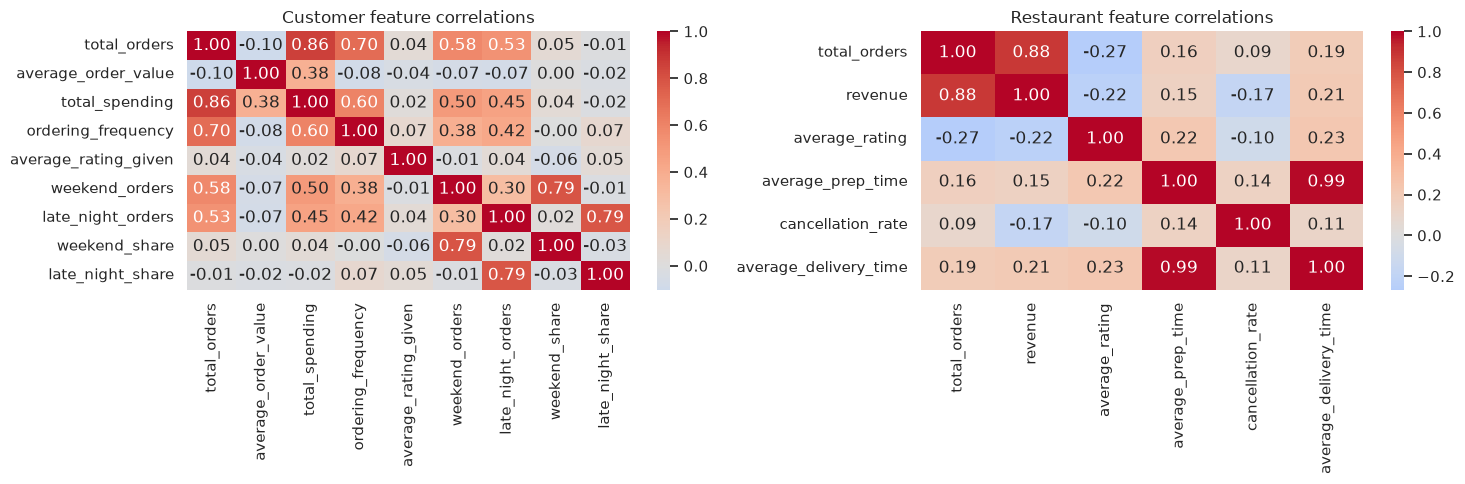

In [5]:
# All orders (incl. cancelled/failed) are needed for volume and cancellation rate
status = orders["order_status"].astype(str).str.lower()
orders["cancelled_flag"] = status.isin({"cancelled", "canceled"}).astype(int)
orders["failed_flag"] = (status == "failed").astype(int)

restaurant_features = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "nunique"),
    cancellation_rate=("cancelled_flag", "mean"),
    failed_rate=("failed_flag", "mean")
).reset_index()

revenue = completed_orders.groupby("restaurant_id")["total_amount"].sum().rename("revenue")
restaurant_features = restaurant_features.merge(revenue, on="restaurant_id", how="left")
restaurant_features["revenue"] = restaurant_features["revenue"].fillna(0)

restaurant_info = restaurants[[
    "restaurant_id", "restaurant_rating", "average_prep_time_minutes",
    "cuisine", "city", "price_level"
]].rename(columns={
    "restaurant_rating": "average_rating",
    "average_prep_time_minutes": "average_prep_time"
})
restaurant_features = restaurant_features.merge(restaurant_info, on="restaurant_id", how="left")

delivery_times = deliveries.merge(
    completed_orders[["order_id", "restaurant_id"]], on="order_id", how="inner"
)
restaurant_features["average_delivery_time"] = restaurant_features["restaurant_id"].map(
    delivery_times.groupby("restaurant_id")["delivery_time_minutes"].mean()
)

# One representative per correlated group
customer_feature_cols = [
    "total_orders", "average_order_value", "average_rating_given",
    "weekend_share", "late_night_share"
]
restaurant_feature_cols = [
    "total_orders", "revenue", "average_rating", "average_prep_time",
    "cancellation_rate", "average_delivery_time"
]
print("Identifiers excluded from models:",
      "customer_id" not in customer_feature_cols and
      "restaurant_id" not in restaurant_feature_cols)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(
    customer_features[["total_orders", "average_order_value", "total_spending",
                       "ordering_frequency", "average_rating_given",
                       "weekend_orders", "late_night_orders",
                       "weekend_share", "late_night_share"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0]
)
axes[0].set_title("Customer feature correlations")
sns.heatmap(
    restaurant_features[restaurant_feature_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]
)
axes[1].set_title("Restaurant feature correlations")
plt.tight_layout()
plt.show()

### 1.2 Missing values and scaling

In [6]:
def prepare_features(df, feature_cols):
    X = df[feature_cols].copy()
    for col in X.columns:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan)

    empty_cols = X.columns[X.isna().all()].tolist()
    if empty_cols:
        raise ValueError(f"These features contain no usable values: {empty_cols}")

    imputer = SimpleImputer(strategy="median")
    X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)
    return X_imputed, X_scaled, imputer, scaler


customer_X, customer_scaled, customer_imputer, customer_scaler = (
    prepare_features(customer_features, customer_feature_cols)
)
restaurant_X, restaurant_scaled, restaurant_imputer, restaurant_scaler = (
    prepare_features(restaurant_features, restaurant_feature_cols)
)

print("Customer model matrix:", customer_scaled.shape)
print("Restaurant model matrix:", restaurant_scaled.shape)
print("\nScaled customer feature mean / std:")
print(pd.DataFrame({
    "mean": customer_scaled.mean(axis=0),
    "std": customer_scaled.std(axis=0)
}, index=customer_X.columns).round(2))

Customer model matrix: (500, 5)
Restaurant model matrix: (50, 6)

Scaled customer feature mean / std:
                      mean  std
total_orders          -0.0  1.0
average_order_value    0.0  1.0
average_rating_given   0.0  1.0
weekend_share          0.0  1.0
late_night_share      -0.0  1.0


### 1.3 K-Means – elbow and silhouette

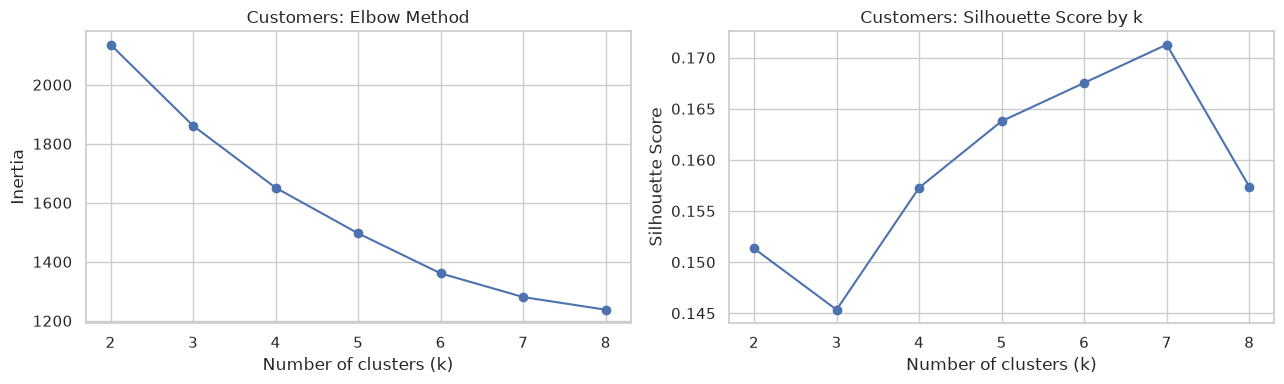

,k,inertia,silhouette_score
0,2,2135.955,0.151
1,3,1861.059,0.145
2,4,1650.959,0.157
3,5,1496.393,0.164
4,6,1360.691,0.168
5,7,1280.411,0.171
6,8,1237.590,0.157


Highest silhouette score at k = 7


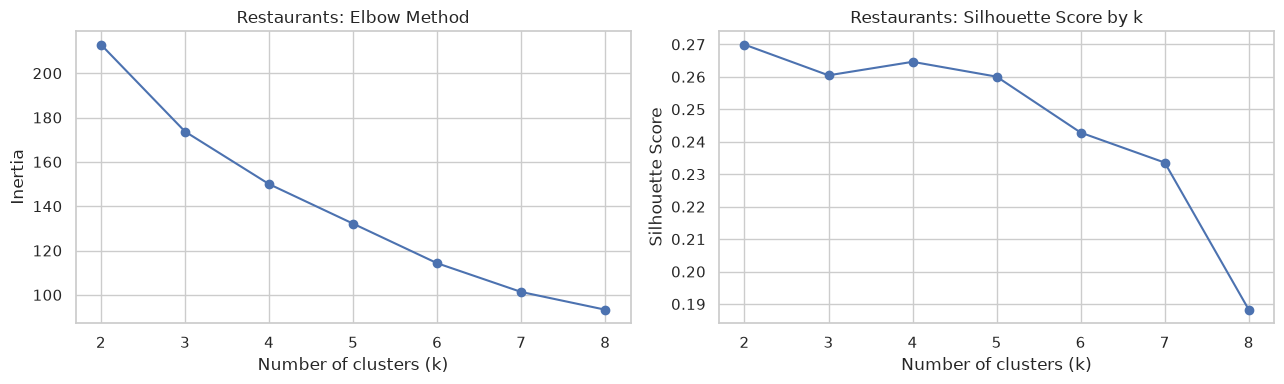

,k,inertia,silhouette_score
0,2,212.894,0.270
1,3,173.670,0.260
2,4,149.957,0.265
3,5,132.111,0.260
4,6,114.273,0.243
5,7,101.309,0.234
6,8,93.307,0.188


Highest silhouette score at k = 2


In [7]:
def evaluate_kmeans(X_scaled, prefix, max_k=8):
    max_k = min(max_k, len(X_scaled) - 1)
    k_values = range(2, max_k + 1)
    results = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = model.fit_predict(X_scaled)
        results.append({"k": k, "inertia": model.inertia_,
                        "silhouette_score": silhouette_score(X_scaled, labels)})
    scores_df = pd.DataFrame(results)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(scores_df["k"], scores_df["inertia"], marker="o")
    axes[0].set_title(f"{prefix}: Elbow Method")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Inertia")
    axes[1].plot(scores_df["k"], scores_df["silhouette_score"], marker="o")
    axes[1].set_title(f"{prefix}: Silhouette Score by k")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("Silhouette Score")
    plt.tight_layout()
    plt.show()

    display(scores_df.round(3))
    best_k = int(scores_df.loc[scores_df["silhouette_score"].idxmax(), "k"])
    print(f"Highest silhouette score at k = {best_k}")
    return scores_df, best_k


customer_k_results, best_customer_k = evaluate_kmeans(customer_scaled, "Customers")
restaurant_k_results, best_restaurant_k = evaluate_kmeans(restaurant_scaled, "Restaurants")

In [8]:
# Final K-Means (same k as Day 2)
CUSTOMER_K = 4
RESTAURANT_K = 3

customer_kmeans = KMeans(n_clusters=CUSTOMER_K, random_state=RANDOM_STATE, n_init=10)
restaurant_kmeans = KMeans(n_clusters=RESTAURANT_K, random_state=RANDOM_STATE, n_init=10)

customer_features["kmeans_cluster"] = customer_kmeans.fit_predict(customer_scaled)
restaurant_features["kmeans_cluster"] = restaurant_kmeans.fit_predict(restaurant_scaled)

customer_sil = silhouette_score(customer_scaled, customer_features["kmeans_cluster"])
restaurant_sil = silhouette_score(restaurant_scaled, restaurant_features["kmeans_cluster"])
print(f"Customer K-Means   (k={CUSTOMER_K}) silhouette score: {customer_sil:.3f}")
print(f"Restaurant K-Means (k={RESTAURANT_K}) silhouette score: {restaurant_sil:.3f}")

print("\nCustomer cluster counts:")
print(customer_features["kmeans_cluster"].value_counts().sort_index())
print("\nRestaurant cluster counts:")
print(restaurant_features["kmeans_cluster"].value_counts().sort_index())

Customer K-Means   (k=4) silhouette score: 0.157
Restaurant K-Means (k=3) silhouette score: 0.260

Customer cluster counts:
kmeans_cluster
0    156
1    119
2    113
3    112
Name: count, dtype: int64

Restaurant cluster counts:
kmeans_cluster
0    20
1    11
2    19
Name: count, dtype: int64


### 1.4 DBSCAN – dense groups, outliers and noise

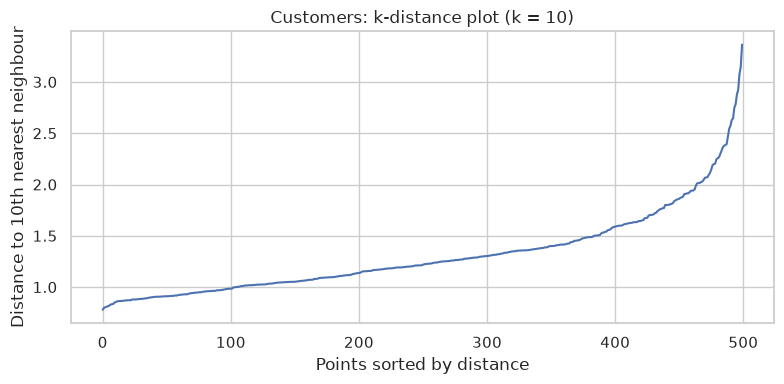


Customers DBSCAN grid (min_samples=10):
 eps  clusters  noise_points  noise_pct  silhouette_excl_noise
 0.8         1           483       96.6                    NaN
 1.0         1           264       52.8                    NaN
 1.2         1           131       26.2                    NaN
 1.4         1            56       11.2                    NaN
 1.6         1            31        6.2                    NaN
 1.8         1            18        3.6                    NaN
 2.0         1             7        1.4                    NaN
 2.2         1             5        1.0                    NaN
 2.4         1             2        0.4                    NaN
 2.6         1             1        0.2                    NaN

Selected eps = 1.6, min_samples = 10
Dense clusters found: 1
Noise / outlier points: 31 (6.2%)
-1     31
 0    469
Silhouette score not defined: DBSCAN found a single dense group plus outliers.


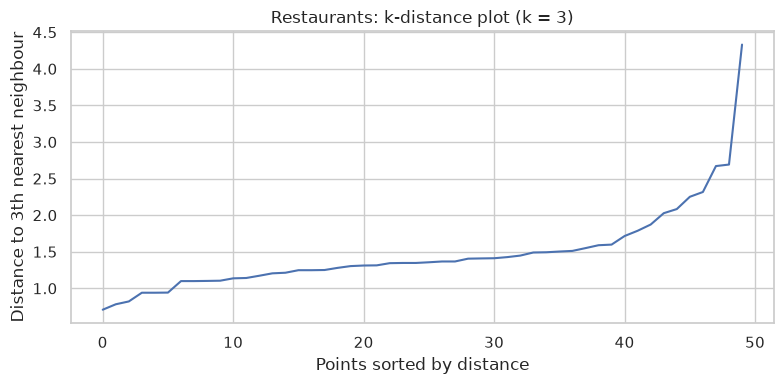


Restaurants DBSCAN grid (min_samples=3):
 eps  clusters  noise_points  noise_pct  silhouette_excl_noise
 1.0         2            41       82.0                  0.698
 1.2         4            28       56.0                  0.294
 1.4         4            12       24.0                  0.249
 1.6         1             7       14.0                    NaN
 1.8         1             7       14.0                    NaN
 2.0         1             6       12.0                    NaN
 2.2         1             4        8.0                    NaN
 2.4         1             2        4.0                    NaN
 2.6         1             2        4.0                    NaN

Selected eps = 1.4, min_samples = 3
Dense clusters found: 4
Noise / outlier points: 12 (24.0%)
-1    12
 0    14
 1    18
 2     3
 3     3
Silhouette score (excluding noise): 0.249

Customer outliers vs core (feature means):


,total_orders,average_order_value,average_rating_given,weekend_share,late_night_share,total_spending
is_outlier,,,,,,
dense core,9.08,812.58,3.99,0.29,0.30,7346.19
outliers (noise),4.84,869.72,3.30,0.33,0.34,4192.60


Restaurant outliers vs dense groups (feature means):


,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time
is_outlier,,,,,,
dense groups,101.47,72489.88,3.93,24.92,0.09,59.83
outliers (noise),95.33,68393.35,3.98,24.17,0.10,59.05


In [9]:
def plot_k_distance(X_scaled, k, prefix):
    distances = np.sort(
        NearestNeighbors(n_neighbors=k).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
    )
    plt.figure(figsize=(8, 4))
    plt.plot(distances)
    plt.title(f"{prefix}: k-distance plot (k = {k})")
    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"Distance to {k}th nearest neighbour")
    plt.tight_layout()
    plt.show()


def tune_dbscan(X_scaled, min_samples, eps_grid, max_noise_pct):
    rows = []
    for eps in eps_grid:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels) - {-1})
        mask = labels != -1
        sil = (silhouette_score(X_scaled[mask], labels[mask])
               if n_clusters >= 2 else np.nan)
        rows.append({"eps": round(eps, 2), "clusters": n_clusters,
                     "noise_points": int((~mask).sum()),
                     "noise_pct": round(100 * (~mask).mean(), 1),
                     "silhouette_excl_noise": sil})
    grid = pd.DataFrame(rows)

    ok = grid[grid["noise_pct"] <= max_noise_pct]
    multi = ok[ok["clusters"] >= 2]
    if len(multi):
        best = multi.loc[multi["silhouette_excl_noise"].idxmax()]
    elif len(ok):
        best = ok.iloc[0]
    else:
        best = grid.iloc[-1]
    return grid, float(best["eps"])


def run_dbscan(X_scaled, prefix, min_samples, eps_grid, max_noise_pct):
    plot_k_distance(X_scaled, min_samples, prefix)
    grid, eps = tune_dbscan(X_scaled, min_samples, eps_grid, max_noise_pct)

    print(f"\n{prefix} DBSCAN grid (min_samples={min_samples}):")
    print(grid.round(3).to_string(index=False))

    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    mask = labels != -1
    n_clusters = len(set(labels) - {-1})

    print(f"\nSelected eps = {eps}, min_samples = {min_samples}")
    print("Dense clusters found:", n_clusters)
    print("Noise / outlier points:", int((~mask).sum()), f"({100 * (~mask).mean():.1f}%)")
    print(pd.Series(labels).value_counts().sort_index().rename("points").to_string())

    if n_clusters >= 2:
        print("Silhouette score (excluding noise):",
              round(silhouette_score(X_scaled[mask], labels[mask]), 3))
    else:
        print("Silhouette score not defined: DBSCAN found a single dense group plus outliers.")
    return model, labels


# Customers: 5 features -> min_samples = 10
customer_dbscan, customer_features["dbscan_cluster"] = run_dbscan(
    customer_scaled, "Customers", min_samples=10,
    eps_grid=np.arange(0.8, 2.61, 0.2), max_noise_pct=10
)

# Restaurants: only 50 points -> small min_samples
restaurant_dbscan, restaurant_features["dbscan_cluster"] = run_dbscan(
    restaurant_scaled, "Restaurants", min_samples=3,
    eps_grid=np.arange(1.0, 2.61, 0.2), max_noise_pct=35
)

customer_features["is_outlier"] = customer_features["dbscan_cluster"] == -1
restaurant_features["is_outlier"] = restaurant_features["dbscan_cluster"] == -1

print("\nCustomer outliers vs core (feature means):")
display(customer_features.groupby("is_outlier")[customer_feature_cols + ["total_spending"]]
        .mean().round(2).rename(index={False: "dense core", True: "outliers (noise)"}))
print("Restaurant outliers vs dense groups (feature means):")
display(restaurant_features.groupby("is_outlier")[restaurant_feature_cols]
        .mean().round(2).rename(index={False: "dense groups", True: "outliers (noise)"}))

### 1.5 PCA visualisation

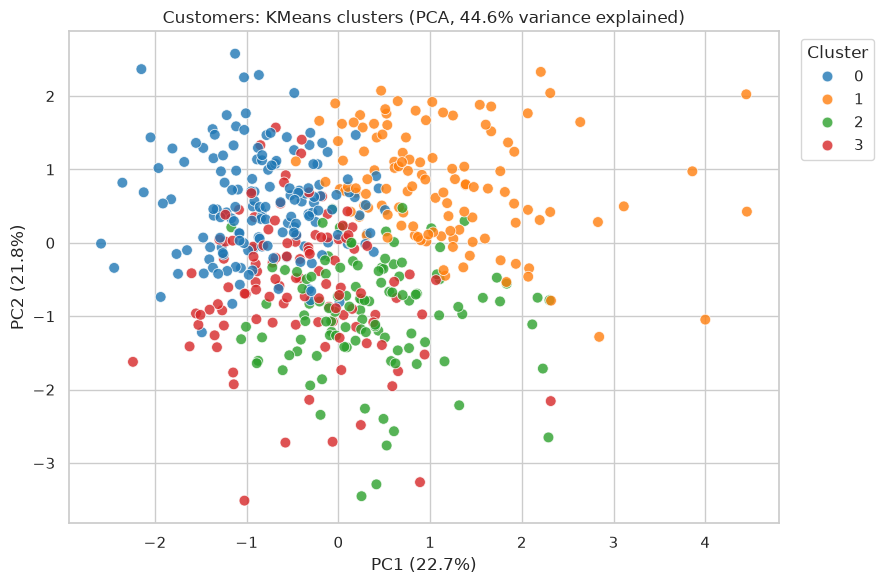

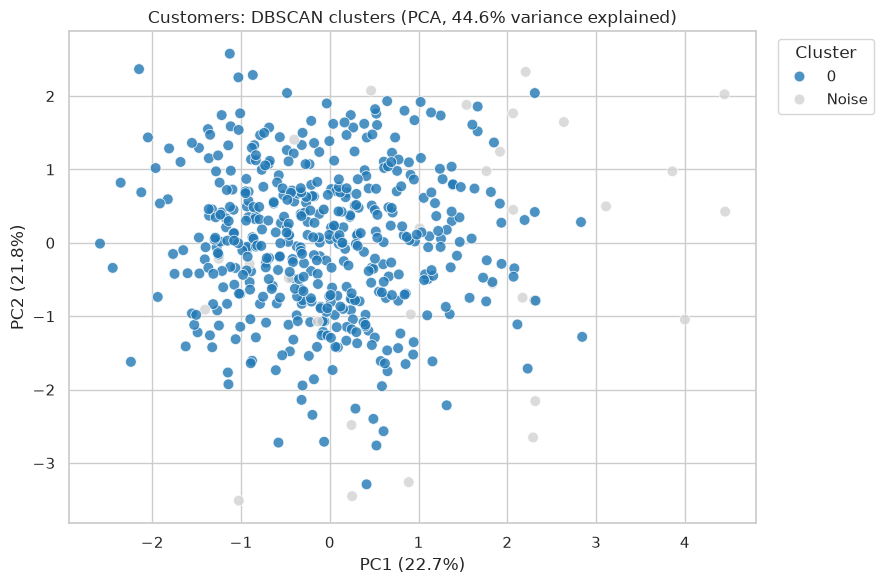

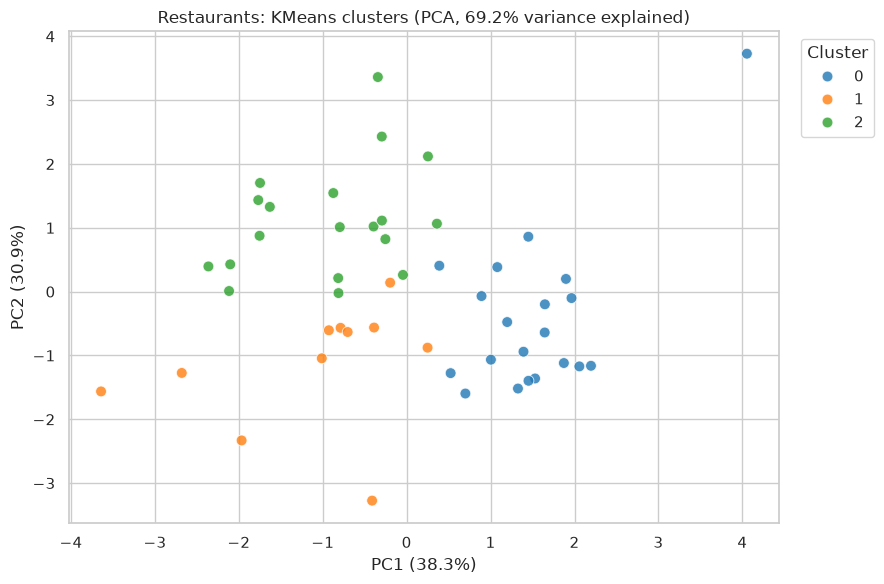

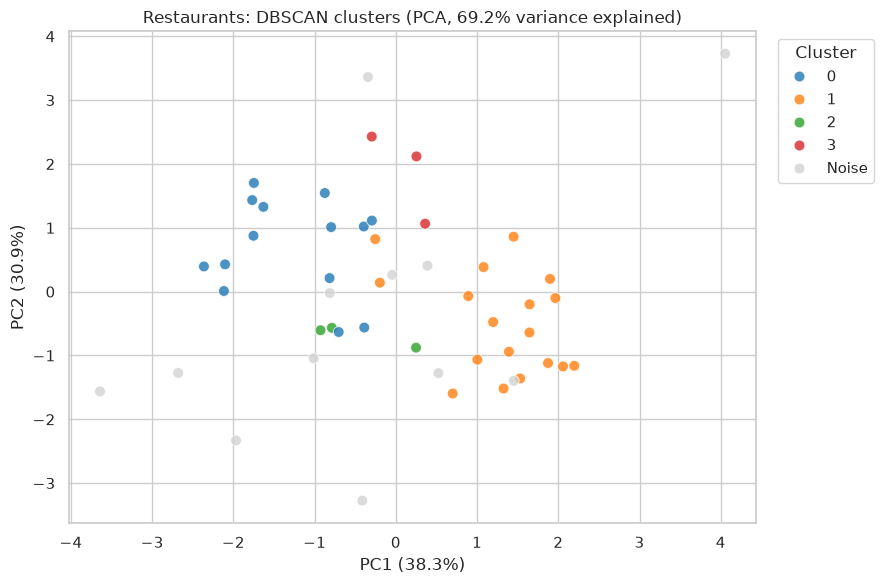

Customer PCA loadings:
                       PC1   PC2
total_orders         -0.56  0.44
average_order_value   0.62 -0.16
average_rating_given -0.48 -0.40
weekend_share         0.08  0.66
late_night_share     -0.25 -0.42

Restaurant PCA loadings:
                        PC1   PC2
total_orders           0.45  0.48
revenue                0.44  0.49
average_rating         0.01 -0.47
average_prep_time      0.54 -0.40
cancellation_rate      0.08 -0.11
average_delivery_time  0.55 -0.37


In [10]:
def plot_pca_clusters(X_scaled, labels, prefix, algorithm):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    components = pca.fit_transform(X_scaled)

    plot_df = pd.DataFrame({
        "PC1": components[:, 0],
        "PC2": components[:, 1],
        "Cluster": np.where(labels == -1, "Noise", labels.astype(str))
    })
    cluster_order = sorted(c for c in plot_df["Cluster"].unique() if c != "Noise")
    palette = dict(zip(cluster_order, sns.color_palette("tab10", len(cluster_order))))
    palette["Noise"] = "lightgrey"

    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=plot_df, x="PC1", y="PC2", hue="Cluster",
        hue_order=cluster_order + (["Noise"] if "Noise" in plot_df["Cluster"].values else []),
        palette=palette, s=60, alpha=0.8
    )
    var = pca.explained_variance_ratio_.sum() * 100
    plt.title(f"{prefix}: {algorithm} clusters (PCA, {var:.1f}% variance explained)")
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return pca


customer_pca = plot_pca_clusters(customer_scaled, customer_features["kmeans_cluster"].to_numpy(), "Customers", "KMeans")
plot_pca_clusters(customer_scaled, customer_features["dbscan_cluster"].to_numpy(), "Customers", "DBSCAN")
restaurant_pca = plot_pca_clusters(restaurant_scaled, restaurant_features["kmeans_cluster"].to_numpy(), "Restaurants", "KMeans")
plot_pca_clusters(restaurant_scaled, restaurant_features["dbscan_cluster"].to_numpy(), "Restaurants", "DBSCAN")

print("Customer PCA loadings:")
print(pd.DataFrame(customer_pca.components_.T, index=customer_X.columns, columns=["PC1", "PC2"]).round(2))
print("\nRestaurant PCA loadings:")
print(pd.DataFrame(restaurant_pca.components_.T, index=restaurant_X.columns, columns=["PC1", "PC2"]).round(2))

### 1.6 Cluster profiles and business names

In [11]:
customer_profile_cols = [
    "total_orders", "average_order_value", "total_spending",
    "ordering_frequency", "average_rating_given",
    "weekend_orders", "late_night_orders",
    "weekend_share", "late_night_share"
]
customer_profiles = (
    customer_features.groupby("kmeans_cluster")[customer_profile_cols].mean().round(2)
)
customer_profiles.insert(0, "n_customers",
                         customer_features["kmeans_cluster"].value_counts().sort_index())

restaurant_profile_cols = [
    "total_orders", "revenue", "average_rating", "average_prep_time",
    "cancellation_rate", "average_delivery_time"
]
restaurant_profiles = (
    restaurant_features.groupby("kmeans_cluster")[restaurant_profile_cols].mean().round(2)
)
restaurant_profiles.insert(0, "n_restaurants",
                           restaurant_features["kmeans_cluster"].value_counts().sort_index())
restaurant_profiles["most_common_cuisine"] = (
    restaurant_features.groupby("kmeans_cluster")["cuisine"].agg(lambda s: s.mode().iloc[0])
)


def name_customer_clusters(profiles):
    names = {}
    remaining = list(profiles.index)
    overall_spend = (profiles["total_spending"] * profiles["n_customers"]).sum() / profiles["n_customers"].sum()
    overall_aov = (profiles["average_order_value"] * profiles["n_customers"]).sum() / profiles["n_customers"].sum()

    c = profiles.loc[remaining, "total_orders"].idxmax()
    names[c] = "Premium Frequent Diners"
    remaining.remove(c)

    if remaining:
        c = profiles.loc[remaining, "late_night_share"].idxmax()
        high_value = profiles.loc[c, "total_spending"] >= overall_spend
        names[c] = ("Late-Night High-Value Customers" if high_value
                    else "Late-Night Budget Customers")
        remaining.remove(c)

    if remaining:
        c = profiles.loc[remaining, "weekend_share"].idxmax()
        big_basket = profiles.loc[c, "average_order_value"] >= overall_aov
        names[c] = ("Weekend High-Ticket Customers" if big_basket
                    else "Weekend Value Seekers")
        remaining.remove(c)

    for c in remaining:
        low_weekend = profiles.loc[c, "weekend_share"] < profiles["weekend_share"].median()
        names[c] = ("Weekday Regular Customers" if low_weekend
                    else "Occasional Customers")
    return names


def name_restaurant_clusters(profiles):
    names = {}
    remaining = list(profiles.index)
    mean_orders = (profiles["total_orders"] * profiles["n_restaurants"]).sum() / profiles["n_restaurants"].sum()

    c = profiles.loc[remaining, "average_prep_time"].idxmax()
    names[c] = "High-Demand Slow-Preparation Restaurants"
    remaining.remove(c)

    if remaining:
        c = profiles.loc[remaining, "average_rating"].idxmax()
        popular = profiles.loc[c, "total_orders"] >= mean_orders
        names[c] = ("High-Performing Popular Restaurants" if popular
                    else "Highly Rated Niche Restaurants")
        remaining.remove(c)

    for c in remaining:
        names[c] = "Fast-Prep Lower-Rated Restaurants"
    return names


customer_cluster_names = name_customer_clusters(customer_profiles)
restaurant_cluster_names = name_restaurant_clusters(restaurant_profiles)

customer_features["customer_segment"] = customer_features["kmeans_cluster"].map(customer_cluster_names)
restaurant_features["restaurant_segment"] = restaurant_features["kmeans_cluster"].map(restaurant_cluster_names)

print("Customer segment names:")
for cluster_id, name in sorted(customer_cluster_names.items()):
    print(f"  Cluster {cluster_id}: {name}")
print("Restaurant segment names:")
for cluster_id, name in sorted(restaurant_cluster_names.items()):
    print(f"  Cluster {cluster_id}: {name}")

display(customer_profiles)
display(restaurant_profiles)
display(customer_features["customer_segment"].value_counts().rename("customers").to_frame())
display(restaurant_features["restaurant_segment"].value_counts().rename("restaurants").to_frame())

Customer segment names:
  Cluster 0: Premium Frequent Diners
  Cluster 1: Weekend High-Ticket Customers
  Cluster 2: Weekday Regular Customers
  Cluster 3: Late-Night Budget Customers
Restaurant segment names:
  Cluster 0: High-Demand Slow-Preparation Restaurants
  Cluster 1: Highly Rated Niche Restaurants
  Cluster 2: Fast-Prep Lower-Rated Restaurants


,n_customers,total_orders,average_order_value,total_spending,ordering_frequency,average_rating_given,weekend_orders,late_night_orders,weekend_share,late_night_share
kmeans_cluster,,,,,,,,,,
0,156,11.98,779.62,9385.05,2.31,4.08,3.47,3.38,0.29,0.28
1,119,7.60,886.95,6654.26,1.73,3.26,2.99,1.81,0.40,0.23
2,113,7.04,852.54,6043.96,1.72,4.21,0.93,1.60,0.13,0.23
3,112,7.52,754.95,5682.52,1.79,4.22,2.51,3.55,0.33,0.48


,n_restaurants,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time,most_common_cuisine
kmeans_cluster,,,,,,,,
0,20,105.75,76314.39,4.16,33.70,0.09,68.40,Biryani
1,11,86.73,61231.52,4.16,24.27,0.07,58.70,Biryani
2,19,101.63,72394.79,3.59,15.58,0.09,50.98,Desserts


,customers
customer_segment,
Premium Frequent Diners,156
Weekend High-Ticket Customers,119
Weekday Regular Customers,113
Late-Night Budget Customers,112


,restaurants
restaurant_segment,
High-Demand Slow-Preparation Restaurants,20
Fast-Prep Lower-Rated Restaurants,19
Highly Rated Niche Restaurants,11


# Step 2 – Customer Feedback Analysis (NLP)

### 2.1 Review cleaning and sentiment labels

In [13]:
TEXT_COL = "review_text"
RATING_COL = "rating"

print("Missing review texts:", reviews[TEXT_COL].isna().sum())
print("Missing ratings:", reviews[RATING_COL].isna().sum())
print("Duplicate review texts:", reviews[TEXT_COL].duplicated().sum())

reviews = reviews.dropna(subset=[TEXT_COL, RATING_COL]).copy()
reviews[TEXT_COL] = reviews[TEXT_COL].astype(str).str.strip()
reviews[RATING_COL] = pd.to_numeric(reviews[RATING_COL], errors="coerce")
reviews = reviews.dropna(subset=[RATING_COL])
reviews = reviews[reviews[TEXT_COL] != ""].copy()

# Rating-derived sentiment labels
reviews["sentiment"] = np.select(
    [
        reviews[RATING_COL].between(1, 2),
        reviews[RATING_COL] == 3,
        reviews[RATING_COL].between(4, 5)
    ],
    ["negative", "neutral", "positive"],
    default="unknown"
)
reviews = reviews[reviews["sentiment"] != "unknown"].copy()

print("Valid rows:", len(reviews))
print("Unique review texts:", reviews[TEXT_COL].nunique())
display(reviews["sentiment"].value_counts().rename_axis("sentiment").reset_index(name="count"))

# Do identical texts carry different ratings?
review_check = (
    reviews.groupby(TEXT_COL, as_index=False)
    .agg(occurrences=(TEXT_COL, "size"),
         unique_ratings=(RATING_COL, "nunique"),
         ratings=(RATING_COL, lambda x: sorted(x.unique())),
         sentiments=("sentiment", lambda x: sorted(x.unique())))
    .sort_values("occurrences", ascending=False)
)
display(review_check)

Missing review texts: 0
Missing ratings: 0
Duplicate review texts: 1969
Valid rows: 1984
Unique review texts: 15


,sentiment,count
0,positive,1436
1,neutral,274
2,negative,274


,review_text,occurrences,unique_ratings,ratings,sentiments
4,Excellent food and service,301,1,[5],[positive]
5,Fast delivery and delicious food,273,1,[5],[positive]
0,Amazing experience,264,1,[5],[positive]
10,Nice experience,216,1,[4],[positive]
14,Would order again,197,1,[4],[positive]
9,Good food and quick delivery,185,1,[4],[positive]
8,Food was okay,97,1,[3],[neutral]
11,Nothing special,90,1,[3],[neutral]
1,Average experience,87,1,[3],[neutral]
3,Delivery was slow,69,1,[2],[negative]


,review_text,cleaned_text,rating,sentiment
0,Nothing special,special,3,neutral
1,Fast delivery and delicious food,fast delivery delicious food,5,positive
2,Nice experience,nice experience,4,positive
3,Nice experience,nice experience,4,positive
4,Would order again,order,4,positive
5,Food quality was disappointing,food quality disappointing,2,negative
6,Nice experience,nice experience,4,positive
7,Good food and quick delivery,good food quick delivery,4,positive
8,Would order again,order,4,positive
9,Excellent food and service,excellent food service,5,positive


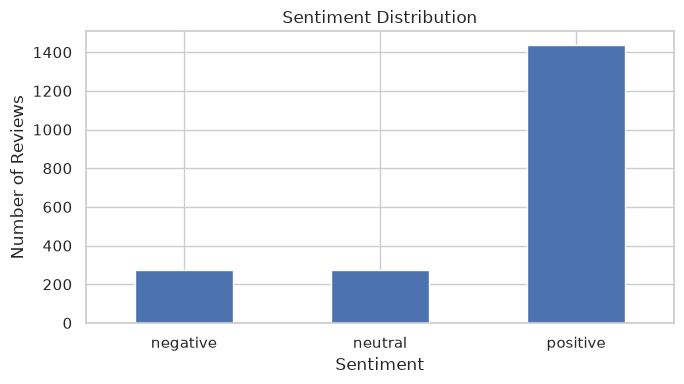

In [14]:
# Stop words (negation words are kept)
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor"}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [word for word in text.split() if word not in stop_words]
    return " ".join(tokens)

reviews["cleaned_text"] = reviews[TEXT_COL].apply(clean_text)
display(reviews[[TEXT_COL, "cleaned_text", RATING_COL, "sentiment"]].head(10))

sentiment_counts = (
    reviews["sentiment"].value_counts()
    .reindex(["negative", "neutral", "positive"], fill_value=0)
)
ax = sentiment_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Sentiment Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.2 TF-IDF + Naive Bayes / Linear SVM

In [15]:
Xs = reviews["cleaned_text"].fillna("")
ys = reviews["sentiment"].astype(str)

if ys.value_counts().min() < 2:
    raise ValueError("Each sentiment class needs at least two examples for a stratified split.")

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.25, random_state=RANDOM_STATE, stratify=ys
)
print("Training rows:", len(Xs_train))
print("Testing rows:", len(Xs_test))

sentiment_models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("model", MultinomialNB())
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("model", LinearSVC(random_state=RANDOM_STATE))
    ])
}

class_order = ["negative", "neutral", "positive"]
sentiment_predictions = {}
sentiment_rows = []

def sentiment_metrics(method, y_true, y_pred):
    return {
        "method": method,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

for model_name, model in sentiment_models.items():
    model.fit(Xs_train, ys_train)
    y_pred = model.predict(Xs_test)
    sentiment_predictions[model_name] = y_pred
    sentiment_rows.append(sentiment_metrics(model_name, ys_test, y_pred))
    print(f"\n--- {model_name} ---")
    print(classification_report(ys_test, y_pred, labels=class_order, zero_division=0))

display(pd.DataFrame(sentiment_rows))

Training rows: 1488
Testing rows: 496

--- Naive Bayes ---
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        69
     neutral       1.00      1.00      1.00        68
    positive       1.00      1.00      1.00       359

    accuracy                           1.00       496
   macro avg       1.00      1.00      1.00       496
weighted avg       1.00      1.00      1.00       496


--- Linear SVM ---
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        69
     neutral       1.00      1.00      1.00        68
    positive       1.00      1.00      1.00       359

    accuracy                           1.00       496
   macro avg       1.00      1.00      1.00       496
weighted avg       1.00      1.00      1.00       496



,method,accuracy,precision_macro,recall_macro,f1_macro
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Linear SVM,1.0,1.0,1.0,1.0


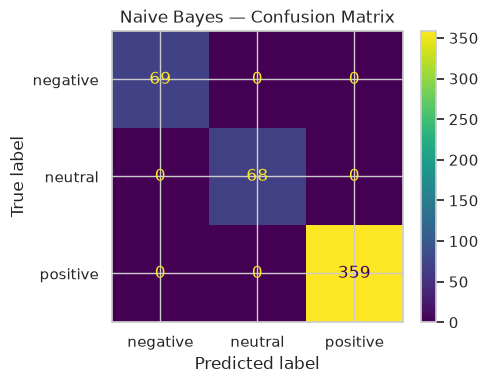

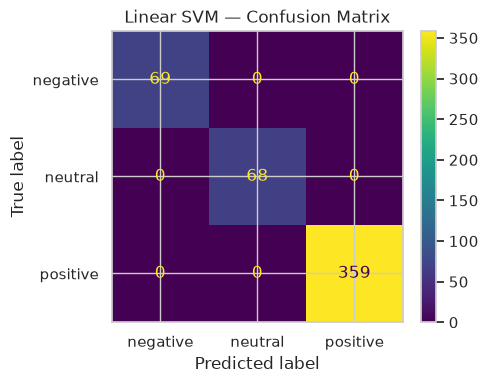

In [16]:
for model_name, y_pred in sentiment_predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        ys_test, y_pred, labels=class_order, display_labels=class_order,
        values_format="d", ax=ax
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

### 2.3 VADER and method comparison

,review_text,rating,sentiment,vader_compound,vader_sentiment
0,Nothing special,3,neutral,-0.3089,negative
1,Fast delivery and delicious food,5,positive,0.5719,positive
2,Nice experience,4,positive,0.4215,positive
3,Nice experience,4,positive,0.4215,positive
4,Would order again,4,positive,0.0000,neutral
5,Food quality was disappointing,2,negative,-0.4939,negative
6,Nice experience,4,positive,0.4215,positive
7,Good food and quick delivery,4,positive,0.4404,positive
8,Would order again,4,positive,0.0000,neutral
9,Excellent food and service,5,positive,0.5719,positive


,method,accuracy,precision_macro,recall_macro,f1_macro
0,Naive Bayes,1.000000,1.000000,1.000000,1.000000
1,Linear SVM,1.000000,1.000000,1.000000,1.000000
2,VADER,0.737903,0.537504,0.513031,0.519525


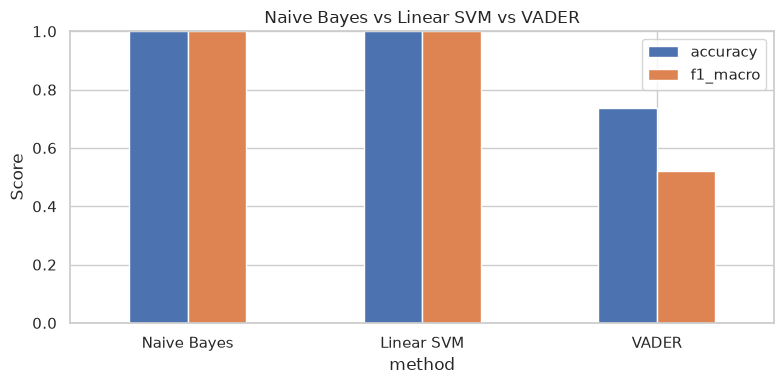

In [17]:
analyzer = SentimentIntensityAnalyzer()

def analyze_vader(text):
    compound_score = analyzer.polarity_scores(str(text))["compound"]
    if compound_score >= 0.05:
        sentiment = "positive"
    elif compound_score <= -0.05:
        sentiment = "negative"
    else:
        sentiment = "neutral"
    return compound_score, sentiment

vader_results = reviews[TEXT_COL].apply(analyze_vader)
reviews["vader_compound"] = [r[0] for r in vader_results]
reviews["vader_sentiment"] = [r[1] for r in vader_results]
display(reviews[[TEXT_COL, RATING_COL, "sentiment", "vader_compound", "vader_sentiment"]].head(10))

vader_test = reviews.loc[Xs_test.index, "vader_sentiment"].astype(str)
sentiment_comparison = pd.DataFrame(
    sentiment_rows + [sentiment_metrics("VADER", ys_test, vader_test)]
)
display(sentiment_comparison)

ax = sentiment_comparison.set_index("method")[["accuracy", "f1_macro"]].plot(kind="bar", figsize=(8, 4))
ax.set_title("Naive Bayes vs Linear SVM vs VADER")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.4 Top terms and complaint themes

,term,mean_tfidf
19,experience,0.125587
22,food,0.120120
35,order,0.107527
12,delivery,0.082732
1,amazing experience,0.078779
0,amazing,0.078779
18,excellent food,0.074640
17,excellent,0.074640
27,food service,0.074640
40,service,0.074640


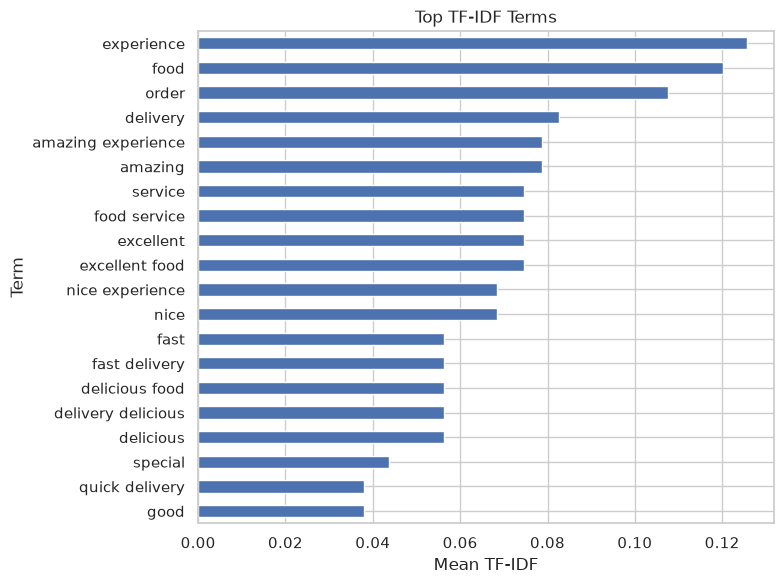

In [18]:
explore_vectorizer = TfidfVectorizer(ngram_range=(1, 2))
train_matrix = explore_vectorizer.fit_transform(Xs_train)
top_terms_df = (
    pd.DataFrame({
        "term": explore_vectorizer.get_feature_names_out(),
        "mean_tfidf": np.asarray(train_matrix.mean(axis=0)).ravel()
    })
    .sort_values("mean_tfidf", ascending=False)
    .head(20)
)
display(top_terms_df)

ax = top_terms_df.sort_values("mean_tfidf").plot(
    x="term", y="mean_tfidf", kind="barh", legend=False, figsize=(8, 6)
)
ax.set_title("Top TF-IDF Terms")
ax.set_xlabel("Mean TF-IDF")
ax.set_ylabel("Term")
plt.tight_layout()
plt.show()

Negative review rows: 274


,review_text,rating,cleaned_text
5,Food quality was disappointing,2,food quality disappointing
17,Food quality was disappointing,2,food quality disappointing
18,Food quality was disappointing,2,food quality disappointing
22,Could be much better,2,better
24,Could be much better,2,better
26,Could be much better,2,better
29,Very late delivery and cold food,1,late delivery cold food
32,Very late delivery and cold food,1,late delivery cold food
37,Very late delivery and cold food,1,late delivery cold food
39,Terrible experience,1,terrible experience


,term,count
0,food,103
1,delivery,96
2,slow,69
3,better,66
4,quality,49
5,disappointing,49
6,terrible,36
7,experience,36
8,late,27
9,cold,27


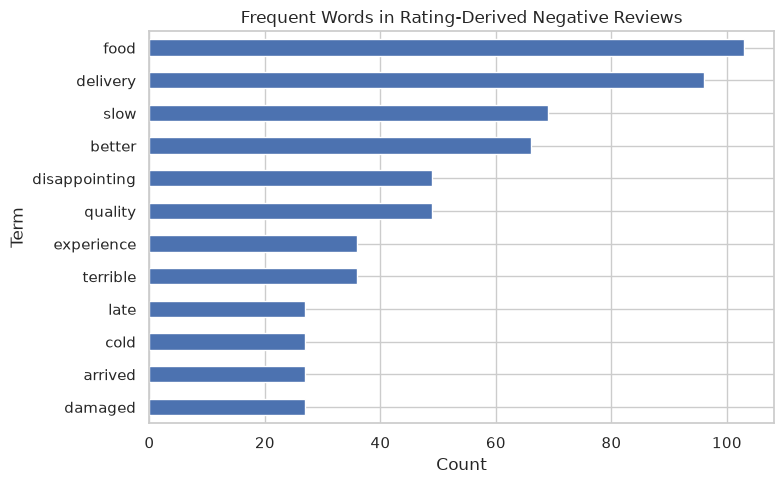

,vader_sentiment,rating
0,negative,2.133663
1,neutral,3.194737
2,positive,4.434379


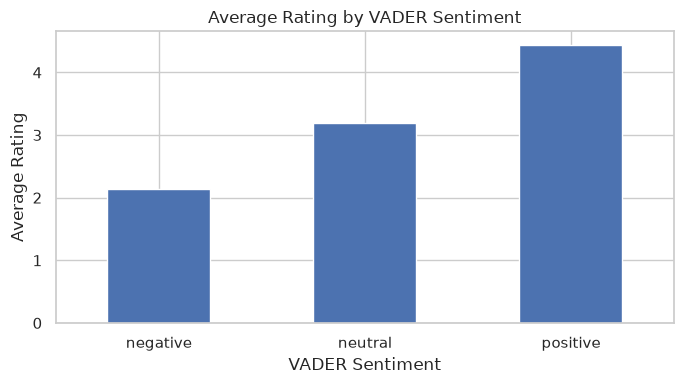

In [19]:
negative_reviews = reviews[reviews["sentiment"] == "negative"].copy()
print("Negative review rows:", len(negative_reviews))
display(negative_reviews[[TEXT_COL, RATING_COL, "cleaned_text"]].head(20))

tokens = [tok for text in negative_reviews["cleaned_text"] for tok in text.split()]
complaint_terms = pd.DataFrame(Counter(tokens).most_common(20), columns=["term", "count"])
display(complaint_terms)

if not complaint_terms.empty:
    ax = complaint_terms.sort_values("count").plot(
        x="term", y="count", kind="barh", legend=False, figsize=(8, 5)
    )
    ax.set_title("Frequent Words in Rating-Derived Negative Reviews")
    ax.set_xlabel("Count")
    ax.set_ylabel("Term")
    plt.tight_layout()
    plt.show()

avg_rating_vader = reviews.groupby("vader_sentiment")[RATING_COL].mean().reset_index()
display(avg_rating_vader)

ax = avg_rating_vader.plot(x="vader_sentiment", y=RATING_COL, kind="bar", legend=False, figsize=(7, 4))
ax.set_title("Average Rating by VADER Sentiment")
ax.set_xlabel("VADER Sentiment")
ax.set_ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 3 – Delivery Time Prediction

### 3.1 Modeling dataset

In [20]:
delivery_df = completed_orders.merge(
    deliveries, on="order_id", how="inner", validate="one_to_one"
)
delivery_df = delivery_df.merge(
    restaurants, on="restaurant_id", how="left",
    validate="many_to_one", suffixes=("", "_restaurant")
)
delivery_df = delivery_df.merge(
    customers, on="customer_id", how="left",
    validate="many_to_one", suffixes=("", "_customer")
)
delivery_df = delivery_df.merge(
    drivers, on="driver_id", how="left",
    validate="many_to_one", suffixes=("", "_driver")
)

print("Modeling dataset shape:", delivery_df.shape)
display(delivery_df.head())

Modeling dataset shape: (4410, 38)


,order_id,customer_id,restaurant_id,order_timestamp,item_count,order_status,order_amount,discount,delivery_fee,tax,...,price_level,age,gender,city_customer,membership_type,signup_date,city_driver,vehicle_type,experience_months,driver_rating
0,O000001,C0400,R008,2026-05-25 01:22:00,2,Delivered,474.01,23.70,20,23.70,...,Moderate,26,Female,Pune,Regular,2025-06-12,Bengaluru,Bike,24,4.2
1,O000002,C0308,R022,2026-05-29 20:41:00,7,Delivered,1476.33,73.82,30,73.82,...,Premium,34,Female,Bengaluru,Gold,2025-07-02,Pune,Scooter,49,3.7
2,O000003,C0029,R025,2026-07-08 13:58:00,1,Delivered,154.74,7.74,50,7.74,...,Budget,59,Female,Bengaluru,Gold,2026-03-25,Bengaluru,Bike,36,4.1
3,O000004,C0144,R002,2026-07-23 19:04:00,1,Delivered,144.95,14.50,40,7.25,...,Moderate,30,Female,Mumbai,Regular,2026-01-27,Delhi,Bike,44,4.1
4,O000005,C0076,R009,2026-09-26 09:50:00,7,Delivered,1424.06,71.20,40,71.20,...,Moderate,41,Female,Delhi,Regular,2025-11-25,Delhi,Bike,27,3.6


### 3.2 EDA

count    4410.000000
mean       59.786848
std        17.274429
min        10.000000
25%        48.000000
50%        60.000000
75%        72.000000
max       114.000000
Name: delivery_time_minutes, dtype: float64


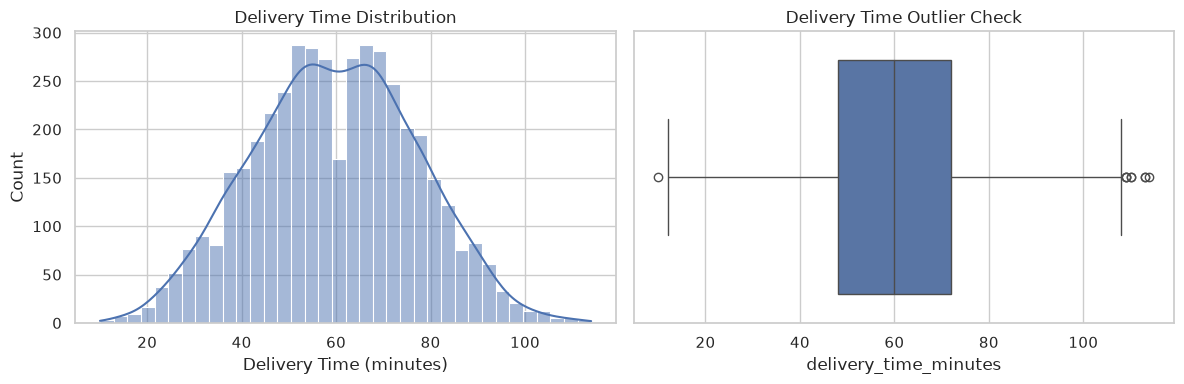

In [21]:
target = "delivery_time_minutes"
print(delivery_df[target].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(delivery_df[target], kde=True, ax=axes[0])
axes[0].set_title("Delivery Time Distribution")
axes[0].set_xlabel("Delivery Time (minutes)")
sns.boxplot(x=delivery_df[target], ax=axes[1])
axes[1].set_title("Delivery Time Outlier Check")
plt.tight_layout()
plt.show()

,correlation
distance_km,0.675560
prep_time_minutes,0.544180
average_prep_time_minutes,0.518093
restaurant_rating,0.129399
driver_rating,0.011493
item_count,0.005152
experience_months,0.003400
delivery_fee,0.002366
weekend_flag,-0.000038
late_night_flag,-0.001675


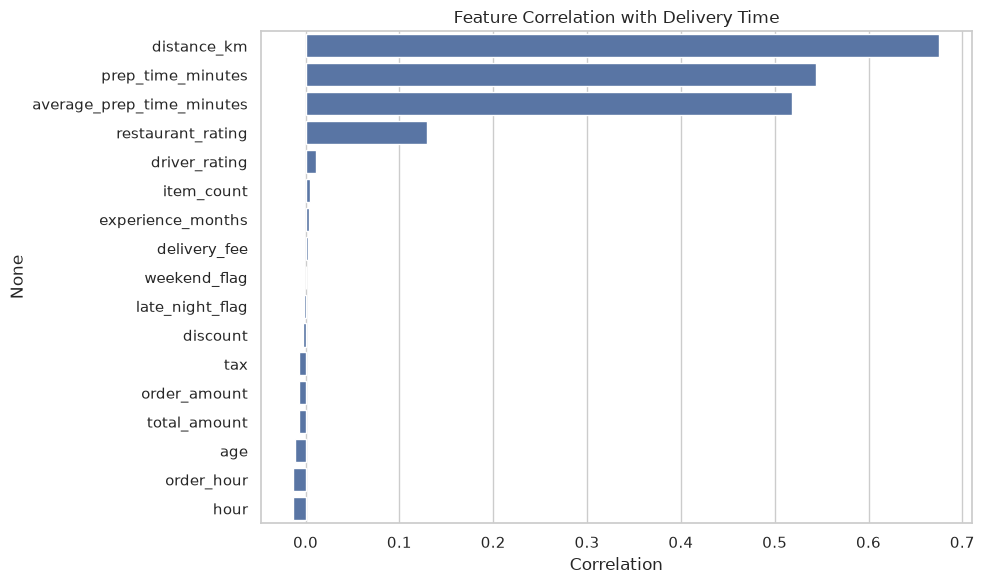

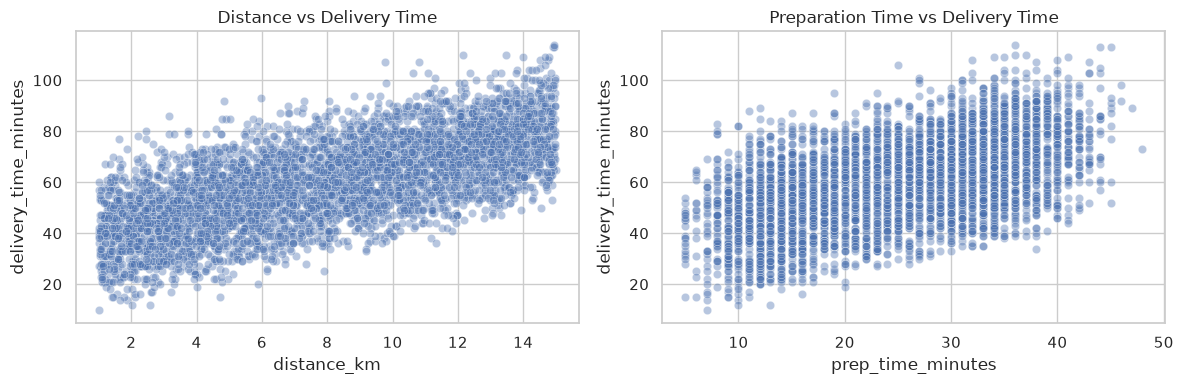

In [22]:
numeric_df = delivery_df.select_dtypes(include=np.number)
correlations = numeric_df.corr()[target].drop(target).sort_values(ascending=False)
display(correlations.to_frame("correlation"))

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Feature Correlation with Delivery Time")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=delivery_df, x="distance_km", y=target, alpha=0.4, ax=axes[0])
axes[0].set_title("Distance vs Delivery Time")
sns.scatterplot(data=delivery_df, x="prep_time_minutes", y=target, alpha=0.4, ax=axes[1])
axes[1].set_title("Preparation Time vs Delivery Time")
plt.tight_layout()
plt.show()

### 3.3 Baseline, Ridge, Lasso, Random Forest

In [23]:
numeric_features = ["distance_km", "prep_time_minutes", "item_count", "order_amount"]
categorical_features = ["weather", "traffic"]
delivery_features = numeric_features + categorical_features

model_df = delivery_df[delivery_features + [target]].dropna(subset=[target]).copy()
Xd = model_df[delivery_features]
yd = model_df[target]

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.2, random_state=RANDOM_STATE
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])
print("Training rows:", len(Xd_train))
print("Testing rows:", len(Xd_test))

delivery_models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=None, min_samples_split=2,
        min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    )
}

fitted_delivery_models = {}
delivery_predictions = {}
delivery_rows = []

for name, model in delivery_models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(Xd_train, yd_train)
    y_pred = pipeline.predict(Xd_test)

    fitted_delivery_models[name] = pipeline
    delivery_predictions[name] = y_pred
    delivery_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(yd_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred)),
        "R2": r2_score(yd_test, y_pred)
    })

delivery_results = pd.DataFrame(delivery_rows).sort_values("RMSE").reset_index(drop=True)
display(delivery_results.round(3))

Training rows: 3528
Testing rows: 882


,Model,MAE,RMSE,R2
0,Ridge Regression,3.232,4.114,0.944
1,Lasso Regression,3.240,4.124,0.943
2,Random Forest,3.600,4.562,0.931
3,Baseline,14.033,17.307,-0.000


In [24]:
# 5-fold cross-validation on the training set
cv_rows = []
for name, pipeline in fitted_delivery_models.items():
    scores = cross_validate(
        pipeline, Xd_train, yd_train, cv=5,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"},
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R2": scores["test_r2"].mean()
    })
delivery_cv = pd.DataFrame(cv_rows).sort_values("CV RMSE")
display(delivery_cv.round(3))

,Model,CV MAE,CV RMSE,CV R2
1,Ridge Regression,3.241,4.055,0.945
2,Lasso Regression,3.257,4.075,0.944
3,Random Forest,3.706,4.658,0.927
0,Baseline,14.101,17.267,-0.002


### 3.4 Feature importance, actual vs predicted, overfitting check

,Feature,Importance
0,num__distance_km,0.4860
1,num__prep_time_minutes,0.3230
7,cat__traffic_High,0.1011
6,cat__weather_Rain,0.0402
3,num__order_amount,0.0126
8,cat__traffic_Low,0.0114
9,cat__traffic_Medium,0.0095
4,cat__weather_Clear,0.0086
2,num__item_count,0.0057
5,cat__weather_Cloudy,0.0018


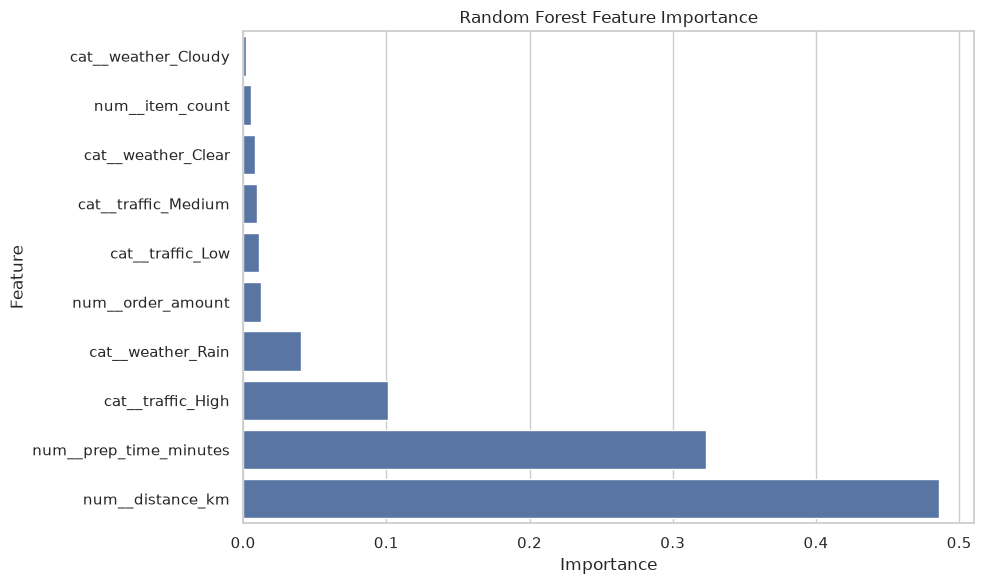

In [25]:
rf_pipeline = fitted_delivery_models["Random Forest"]
rf_importance = pd.DataFrame({
    "Feature": rf_pipeline.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": rf_pipeline.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)
display(rf_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_importance.head(15).sort_values("Importance"), x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

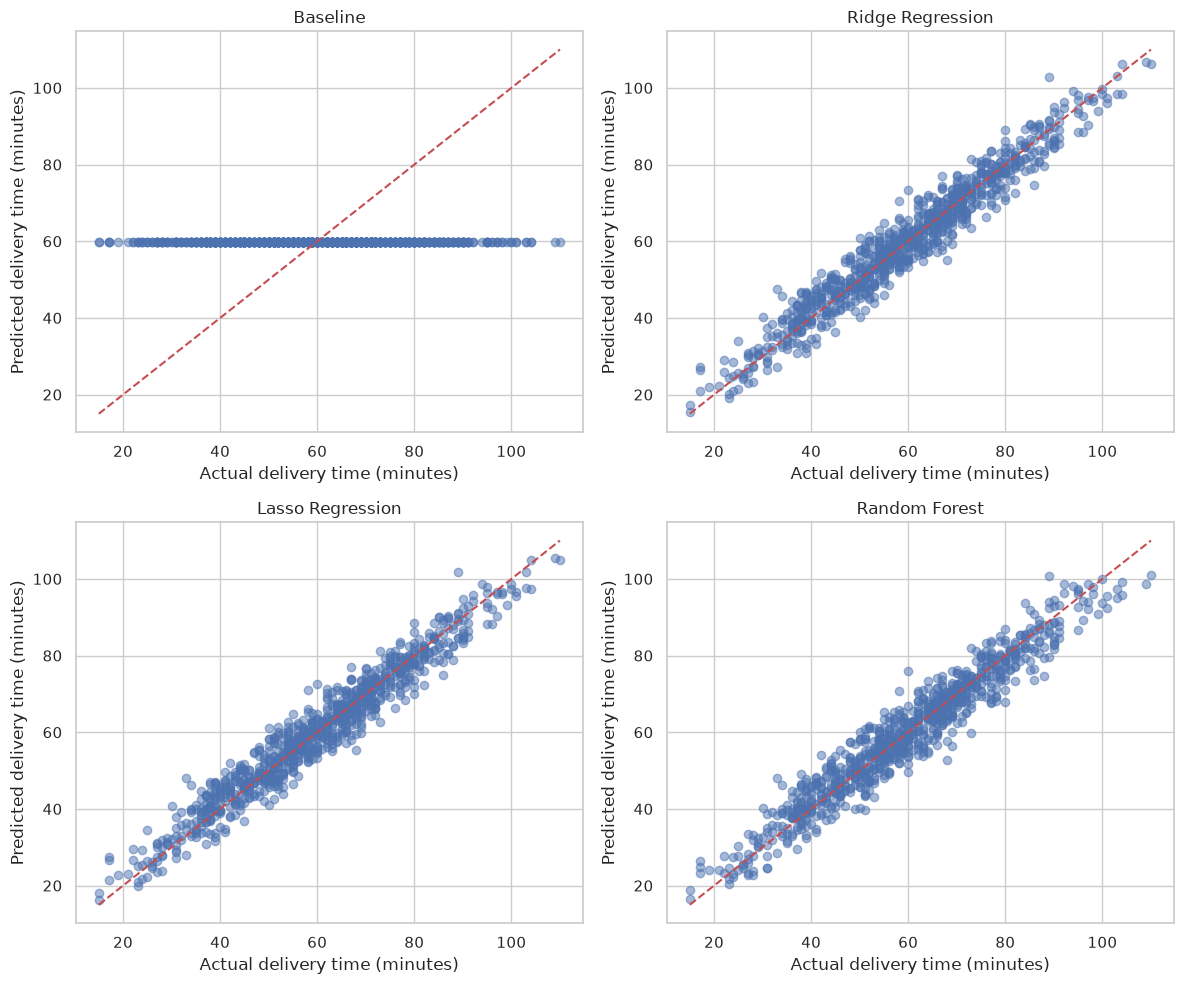

Random Forest training MAE: 1.84
Random Forest testing MAE:  3.6
Random Forest training R2:  0.981
Random Forest testing R2:   0.931


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for ax, (name, y_pred) in zip(axes, delivery_predictions.items()):
    ax.scatter(yd_test, y_pred, alpha=0.5)
    lower = min(yd_test.min(), np.min(y_pred))
    upper = max(yd_test.max(), np.max(y_pred))
    ax.plot([lower, upper], [lower, upper], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual delivery time (minutes)")
    ax.set_ylabel("Predicted delivery time (minutes)")
plt.tight_layout()
plt.show()

train_pred = rf_pipeline.predict(Xd_train)
test_pred = delivery_predictions["Random Forest"]
print("Random Forest training MAE:", round(mean_absolute_error(yd_train, train_pred), 3))
print("Random Forest testing MAE: ", round(mean_absolute_error(yd_test, test_pred), 3))
print("Random Forest training R2: ", round(r2_score(yd_train, train_pred), 3))
print("Random Forest testing R2:  ", round(r2_score(yd_test, test_pred), 3))

,Feature,Coefficient,Absolute_Importance
0,num__distance_km,11.977,11.977
1,num__prep_time_minutes,9.738,9.738
7,cat__traffic_High,8.682,8.682
8,cat__traffic_Low,-7.419,7.419
6,cat__weather_Rain,6.839,6.839
4,cat__weather_Clear,-5.018,5.018
5,cat__weather_Cloudy,-1.821,1.821
9,cat__traffic_Medium,-1.263,1.263
2,num__item_count,0.151,0.151
3,num__order_amount,-0.110,0.110


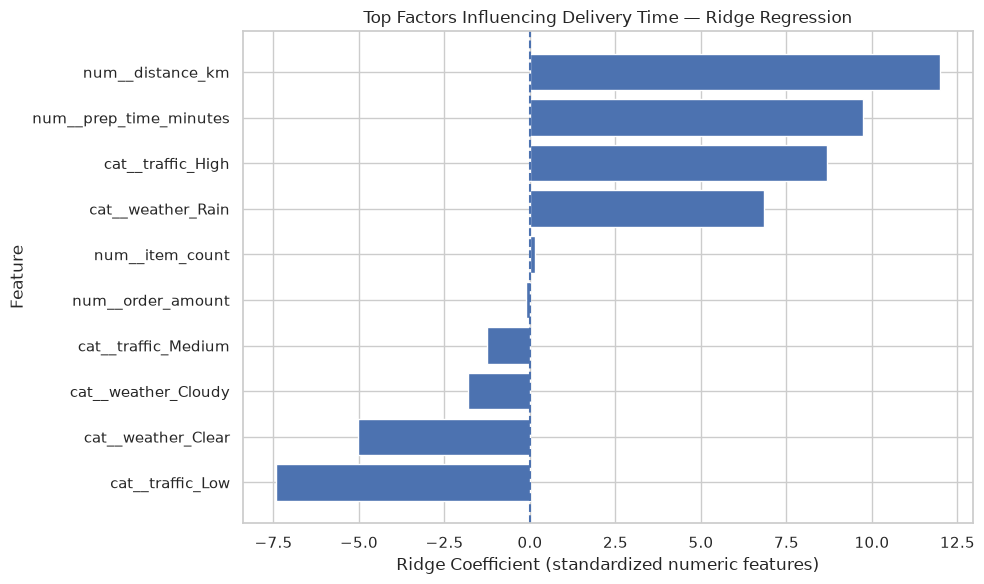

,Actual,Predicted,Residual,Absolute_Error
1413,50,48.61,1.39,1.39
3352,66,70.58,-4.58,4.58
3970,68,68.49,-0.49,0.49
3629,34,38.78,-4.78,4.78
144,63,61.77,1.23,1.23
1746,72,76.39,-4.39,4.39
2154,80,73.88,6.12,6.12
4324,66,62.50,3.50,3.50
4407,83,86.33,-3.33,3.33
2578,60,63.63,-3.63,3.63


Mean residual: -0.276
Mean absolute error: 3.232
Maximum absolute error: 14.561


In [27]:
# Ridge coefficients
ridge_pipeline = fitted_delivery_models["Ridge Regression"]
ridge_importance = pd.DataFrame({
    "Feature": ridge_pipeline.named_steps["preprocessor"].get_feature_names_out(),
    "Coefficient": ridge_pipeline.named_steps["model"].coef_
})
ridge_importance["Absolute_Importance"] = ridge_importance["Coefficient"].abs()
ridge_importance = ridge_importance.sort_values("Absolute_Importance", ascending=False)
display(ridge_importance.head(15).round(3))

top_features = ridge_importance.head(15).sort_values("Coefficient")
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Coefficient"])
plt.axvline(0, linestyle="--")
plt.title("Top Factors Influencing Delivery Time — Ridge Regression")
plt.xlabel("Ridge Coefficient (standardized numeric features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Ridge residuals
residual_df = pd.DataFrame({"Actual": yd_test, "Predicted": delivery_predictions["Ridge Regression"]})
residual_df["Residual"] = residual_df["Actual"] - residual_df["Predicted"]
residual_df["Absolute_Error"] = residual_df["Residual"].abs()
display(residual_df.head(10).round(2))
print("Mean residual:", round(residual_df["Residual"].mean(), 3))
print("Mean absolute error:", round(residual_df["Absolute_Error"].mean(), 3))
print("Maximum absolute error:", round(residual_df["Absolute_Error"].max(), 3))

# Step 4 – Hourly Demand Forecasting

### 4.1 Hourly series and EDA

Hourly dataset shape: (4392, 2)


,order_timestamp,order_count
0,2026-04-01 00:00:00,1
1,2026-04-01 01:00:00,1
2,2026-04-01 02:00:00,2
3,2026-04-01 03:00:00,2
4,2026-04-01 04:00:00,1
5,2026-04-01 05:00:00,2
6,2026-04-01 06:00:00,3
7,2026-04-01 07:00:00,1
8,2026-04-01 08:00:00,1
9,2026-04-01 09:00:00,1


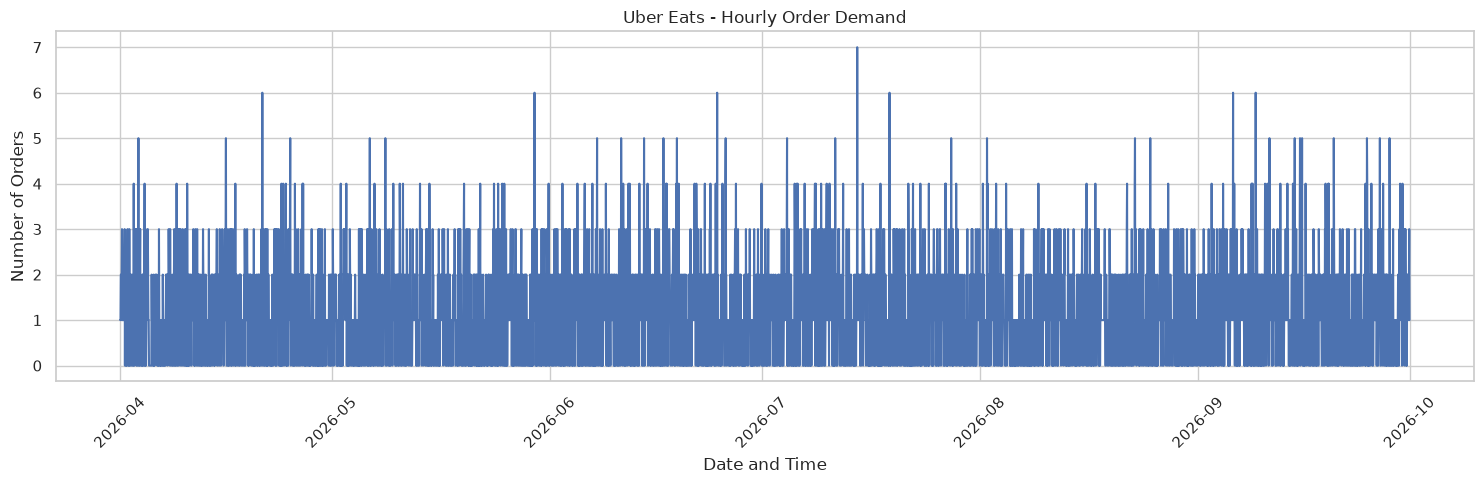

In [28]:
hourly_demand = (
    orders.set_index("order_timestamp")
    .resample("h")
    .size()
    .reset_index(name="order_count")
)
print("Hourly dataset shape:", hourly_demand.shape)
display(hourly_demand.head(10))

plt.figure(figsize=(15, 5))
plt.plot(hourly_demand["order_timestamp"], hourly_demand["order_count"])
plt.title("Uber Eats - Hourly Order Demand")
plt.xlabel("Date and Time")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

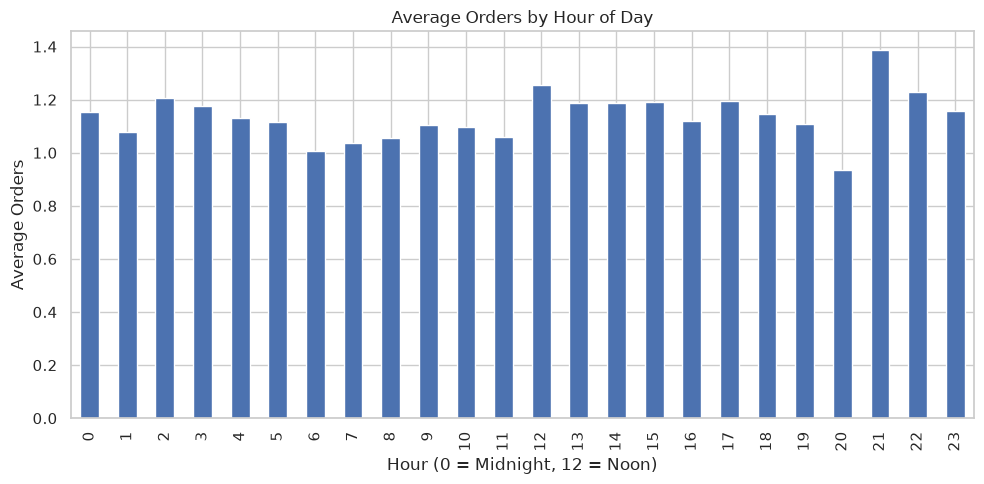

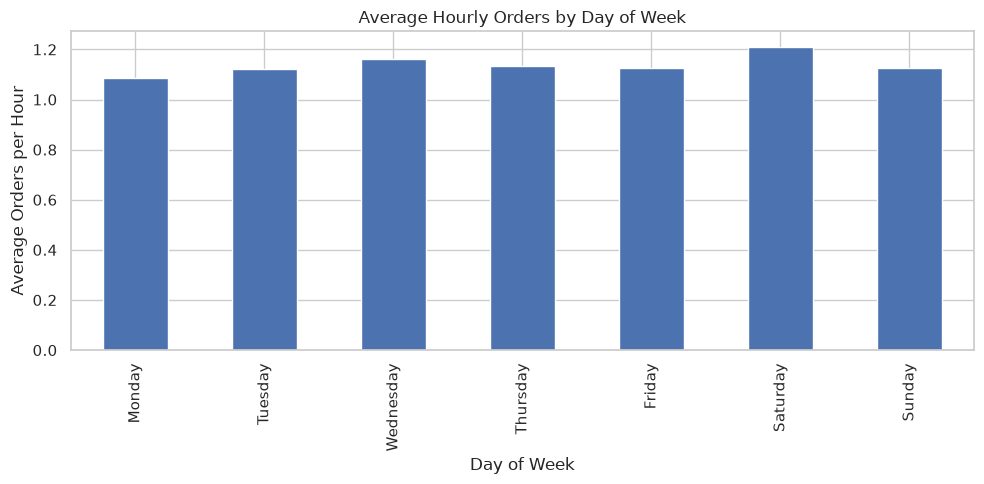

First timestamp: 2026-04-01 00:00:00
Last timestamp: 2026-09-30 23:00:00
Total hourly records: 4392
Missing hourly timestamps: 0
Average orders per hour: 1.14
Maximum orders in an hour: 7
Minimum orders in an hour: 0


In [29]:
hourly_demand["hour"] = hourly_demand["order_timestamp"].dt.hour
hourly_demand["day_of_week"] = hourly_demand["order_timestamp"].dt.day_name()
hourly_demand["date"] = hourly_demand["order_timestamp"].dt.date

hourly_pattern = hourly_demand.groupby("hour")["order_count"].mean()
plt.figure(figsize=(10, 5))
hourly_pattern.plot(kind="bar")
plt.title("Average Orders by Hour of Day")
plt.xlabel("Hour (0 = Midnight, 12 = Noon)")
plt.ylabel("Average Orders")
plt.tight_layout()
plt.show()

daily_pattern = (
    hourly_demand.groupby("day_of_week")["order_count"].mean()
    .reindex(["Monday", "Tuesday", "Wednesday", "Thursday",
              "Friday", "Saturday", "Sunday"])
)
plt.figure(figsize=(10, 5))
daily_pattern.plot(kind="bar")
plt.title("Average Hourly Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Orders per Hour")
plt.tight_layout()
plt.show()

print("First timestamp:", hourly_demand["order_timestamp"].min())
print("Last timestamp:", hourly_demand["order_timestamp"].max())
print("Total hourly records:", len(hourly_demand))
print("Missing hourly timestamps:",
      hourly_demand["order_timestamp"].diff().dropna().ne(pd.Timedelta(hours=1)).sum())
print("Average orders per hour:", round(hourly_demand["order_count"].mean(), 2))
print("Maximum orders in an hour:", hourly_demand["order_count"].max())
print("Minimum orders in an hour:", hourly_demand["order_count"].min())

### 4.2 Decomposition and stationarity

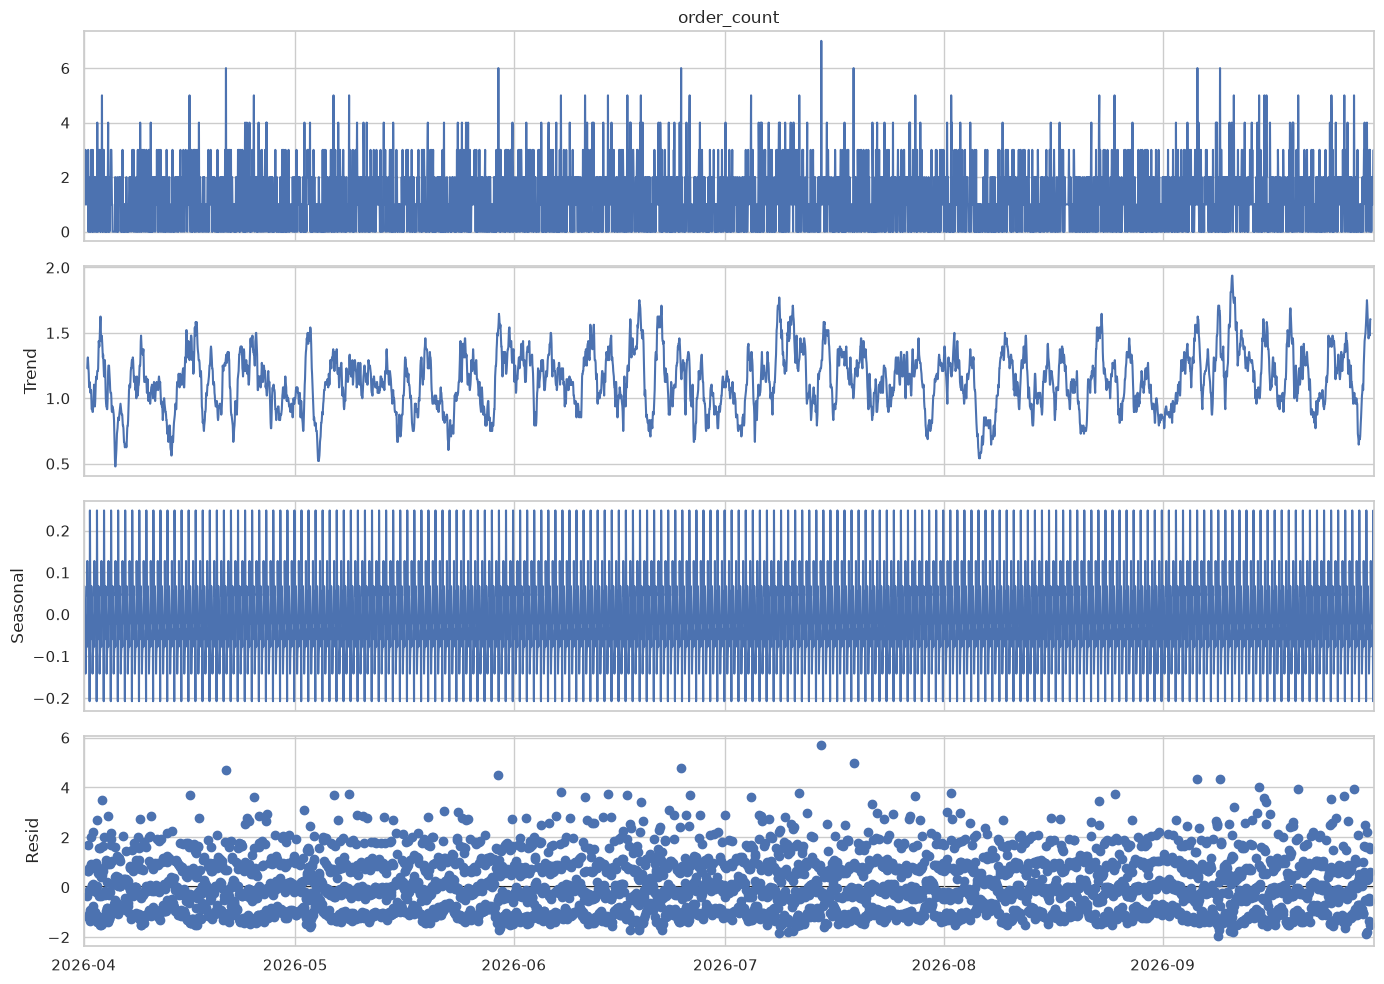

In [30]:
demand_series = hourly_demand.set_index("order_timestamp")["order_count"].asfreq("h")

decomposition = seasonal_decompose(demand_series, model="additive", period=24)
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

ADF Statistic: -34.3815
p-value: 0.0
Critical Value (1%): -3.4318
Critical Value (5%): -2.8622
Critical Value (10%): -2.5671

Conclusion: Reject the unit-root null hypothesis. The series appears stationary under this test.


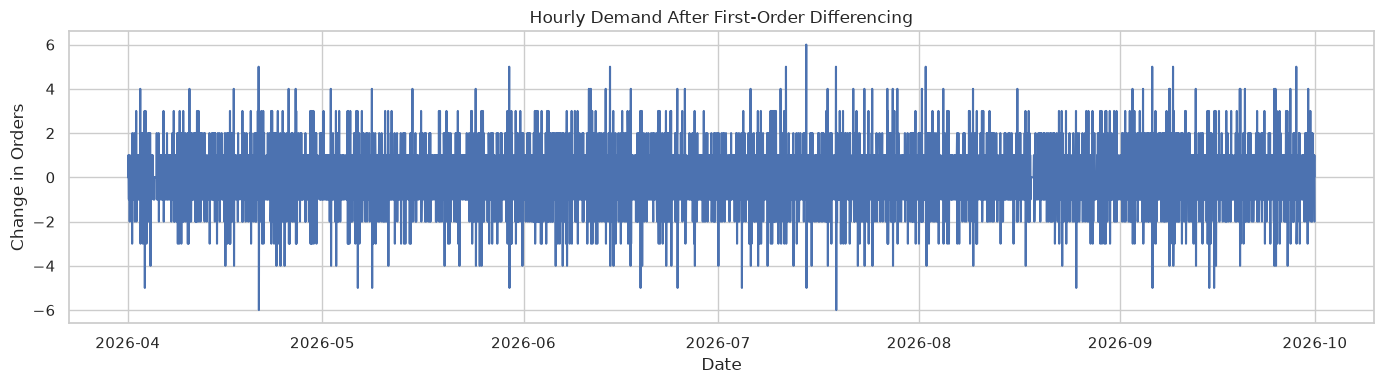

ADF Statistic after differencing: -20.3287
p-value after differencing: 0.0
The differenced series appears stationary under the ADF test.


In [31]:
# ADF test
adf_result = adfuller(demand_series.dropna())
print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical Value (1%):", round(adf_result[4]["1%"], 4))
print("Critical Value (5%):", round(adf_result[4]["5%"], 4))
print("Critical Value (10%):", round(adf_result[4]["10%"], 4))
if adf_result[1] < 0.05:
    print("\nConclusion: Reject the unit-root null hypothesis. The series appears stationary under this test.")
else:
    print("\nConclusion: Fail to reject the unit-root null hypothesis. The series may be non-stationary.")

# First-order differencing
demand_diff = demand_series.diff().dropna()
plt.figure(figsize=(14, 4))
plt.plot(demand_diff)
plt.title("Hourly Demand After First-Order Differencing")
plt.xlabel("Date")
plt.ylabel("Change in Orders")
plt.tight_layout()
plt.show()

diff_adf = adfuller(demand_diff)
print("ADF Statistic after differencing:", round(diff_adf[0], 4))
print("p-value after differencing:", round(diff_adf[1], 4))
if diff_adf[1] < 0.05:
    print("The differenced series appears stationary under the ADF test.")
else:
    print("The differenced series may still be non-stationary.")

### 4.3 Chronological split, ARIMA and Prophet

In [32]:
split_index = int(len(demand_series) * 0.80)
train = demand_series.iloc[:split_index]
test = demand_series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())


def forecast_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    positive = actual > 0
    mape = (np.abs((actual[positive] - predicted[positive]) / actual[positive]).mean() * 100
            if positive.any() else np.nan)
    return mae, rmse, mape


def to_prophet_frame(series):
    frame = series.rename_axis("ds").reset_index()
    frame.columns = ["ds", "y"]
    return frame


def make_prophet():
    return Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False)

Training observations: 3513
Testing observations: 879
Training ends: 2026-08-25 08:00:00
Testing starts: 2026-08-25 09:00:00


                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 3513
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -5250.574
Date:                Fri, 30 Oct 2026   AIC                          10509.148
Time:                        11:19:11   BIC                          10533.805
Sample:                    04-01-2026   HQIC                         10517.946
                         - 08-25-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1249      0.023     49.833      0.000       1.081       1.169
ar.L1         -0.0554      0.627     -0.088      0.930      -1.284       1.173
ma.L1          0.0829      0.626      0.133      0.8

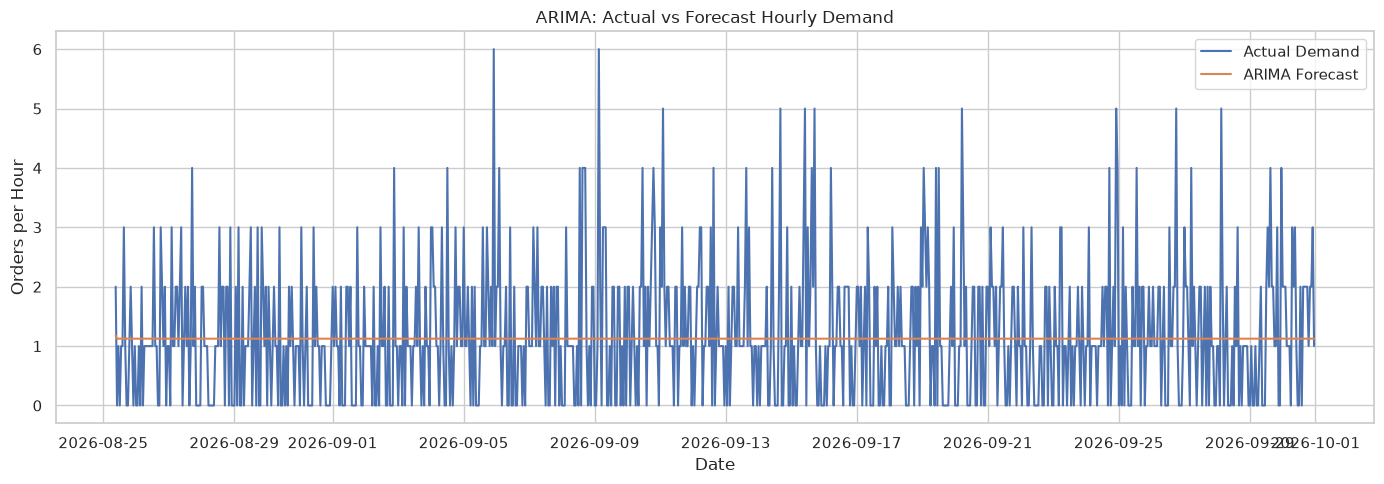

In [33]:
# ARIMA(1, 0, 1)
arima_fit = ARIMA(train, order=(1, 0, 1)).fit()
arima_forecast = arima_fit.forecast(steps=len(test)).clip(lower=0)
print(arima_fit.summary())

arima_mae, arima_rmse, arima_mape = forecast_metrics(test, arima_forecast)
print("\nARIMA MAE:", round(arima_mae, 3))
print("ARIMA RMSE:", round(arima_rmse, 3))
print("ARIMA MAPE on positive-demand hours:", round(arima_mape, 2), "%")

plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual Demand")
plt.plot(test.index, arima_forecast.values, label="ARIMA Forecast")
plt.title("ARIMA: Actual vs Forecast Hourly Demand")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# Prophet
prophet_train = to_prophet_frame(train)
prophet_test = to_prophet_frame(test)

prophet_model = make_prophet()
prophet_model.fit(prophet_train)
prophet_predictions = prophet_model.predict(prophet_test[["ds"]])
prophet_forecast = pd.Series(np.maximum(prophet_predictions["yhat"].to_numpy(), 0), index=test.index)
display(prophet_predictions[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

prophet_mae, prophet_rmse, prophet_mape = forecast_metrics(test, prophet_forecast)
print("Prophet MAE:", round(prophet_mae, 3))
print("Prophet RMSE:", round(prophet_rmse, 3))
print("Prophet MAPE on positive-demand hours:", round(prophet_mape, 2), "%")

11:19:15 - cmdstanpy - INFO - Chain [1] start processing
11:19:15 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
0,2026-08-25 09:00:00,1.111851,-0.364873,2.393680
1,2026-08-25 10:00:00,1.158744,-0.284018,2.518836
2,2026-08-25 11:00:00,1.179687,-0.246234,2.560250
3,2026-08-25 12:00:00,1.191146,-0.206954,2.537782
4,2026-08-25 13:00:00,1.211360,-0.078758,2.632959


Prophet MAE: 0.866
Prophet RMSE: 1.124
Prophet MAPE on positive-demand hours: 32.13 %


### 4.4 Seasonal-naive baseline and model comparison

Seasonal-naive MAE: 1.231
Seasonal-naive RMSE: 1.614
Seasonal-naive MAPE: 72.0 %


,Model,MAE,RMSE,MAPE_positive_hours
0,"ARIMA(1,0,1)",0.860,1.122,31.712
1,Prophet,0.866,1.124,32.126
2,Seasonal Naive (168 hours),1.231,1.614,71.998


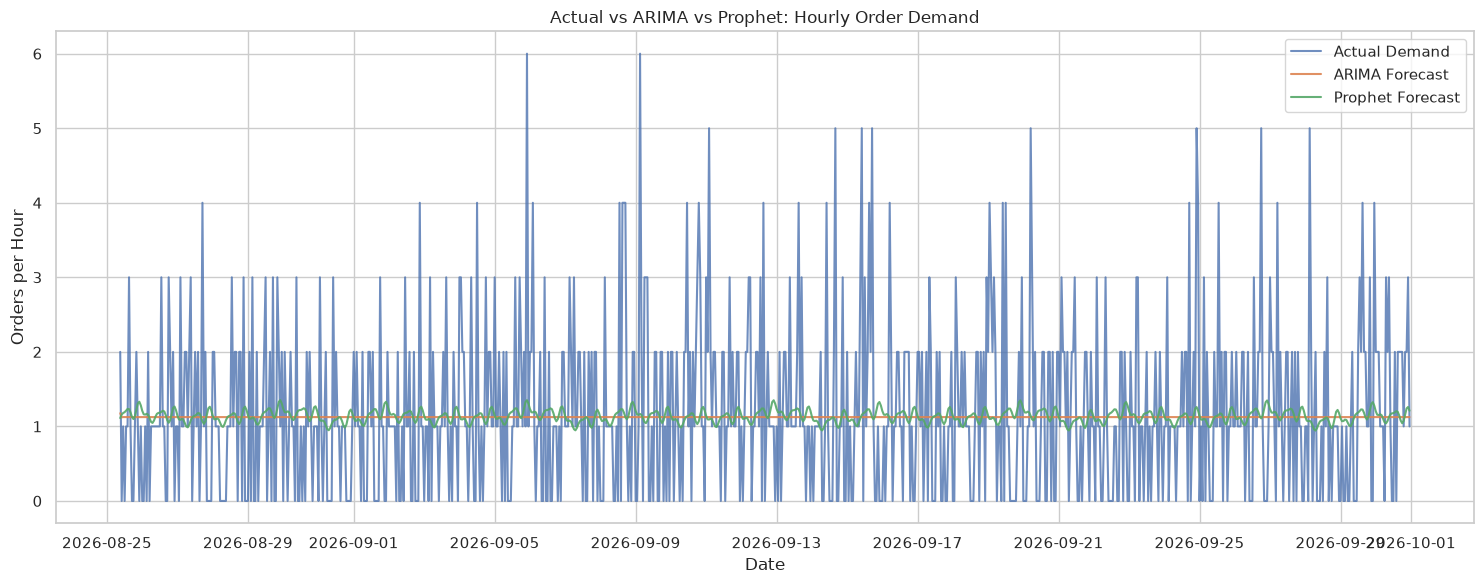

In [35]:
# Same hour in the previous week (168 hours)
baseline_forecast = demand_series.shift(168).loc[test.index]
valid = baseline_forecast.notna()
baseline_mae, baseline_rmse, baseline_mape = forecast_metrics(test.loc[valid], baseline_forecast.loc[valid])
print("Seasonal-naive MAE:", round(baseline_mae, 3))
print("Seasonal-naive RMSE:", round(baseline_rmse, 3))
print("Seasonal-naive MAPE:", round(baseline_mape, 2), "%")

demand_comparison = pd.DataFrame({
    "Model": ["ARIMA(1,0,1)", "Prophet", "Seasonal Naive (168 hours)"],
    "MAE": [arima_mae, prophet_mae, baseline_mae],
    "RMSE": [arima_rmse, prophet_rmse, baseline_rmse],
    "MAPE_positive_hours": [arima_mape, prophet_mape, baseline_mape]
})
display(demand_comparison.round(3))

plt.figure(figsize=(15, 6))
plt.plot(test.index, test.values, label="Actual Demand", alpha=0.8)
plt.plot(test.index, arima_forecast.values, label="ARIMA Forecast", alpha=0.9)
plt.plot(test.index, prophet_forecast.values, label="Prophet Forecast", alpha=0.9)
plt.title("Actual vs ARIMA vs Prophet: Hourly Order Demand")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()
plt.show()

# Step 5 – Evaluation and Prediction

### 5.1 Model comparison summary

In [36]:
segmentation_summary = pd.DataFrame({
    "Entity": ["Customers", "Restaurants"],
    "Model features": [len(customer_feature_cols), len(restaurant_feature_cols)],
    "K-Means k": [CUSTOMER_K, RESTAURANT_K],
    "K-Means silhouette": [round(customer_sil, 3), round(restaurant_sil, 3)],
    "DBSCAN clusters": [len(set(customer_features["dbscan_cluster"]) - {-1}),
                        len(set(restaurant_features["dbscan_cluster"]) - {-1})],
    "DBSCAN outliers": [int(customer_features["is_outlier"].sum()),
                        int(restaurant_features["is_outlier"].sum())],
})
display(segmentation_summary)


def rank_models(frame, model_col, metric_col, higher_is_better, task):
    ranked = frame[[model_col, metric_col]].copy()
    ranked.columns = ["Model", "Value"]
    ranked.insert(0, "Metric", metric_col)
    ranked.insert(0, "Task", task)
    ranked["Rank"] = ranked["Value"].rank(ascending=not higher_is_better, method="first").astype(int)
    return ranked.sort_values("Rank")

model_comparison_summary = pd.concat([
    rank_models(sentiment_comparison, "method", "f1_macro", True, "Sentiment analysis"),
    rank_models(delivery_results, "Model", "RMSE", False, "Delivery time prediction"),
    rank_models(demand_comparison, "Model", "RMSE", False, "Demand forecasting"),
], ignore_index=True)
model_comparison_summary["Selected"] = model_comparison_summary["Rank"] == 1
display(model_comparison_summary.round(3))

best_sentiment_model = sentiment_comparison.sort_values("f1_macro", ascending=False).iloc[0]["method"]
best_delivery_model = delivery_results.iloc[0]["Model"]
best_demand_model = demand_comparison.sort_values("RMSE").iloc[0]["Model"]

print("Selected sentiment model:", best_sentiment_model)
print("Selected delivery model: ", best_delivery_model)
print("Selected demand model:   ", best_demand_model)

,Entity,Model features,K-Means k,K-Means silhouette,DBSCAN clusters,DBSCAN outliers
0,Customers,5,4,0.157,1,31
1,Restaurants,6,3,0.260,4,12


,Task,Metric,Model,Value,Rank,Selected
0,Sentiment analysis,f1_macro,Naive Bayes,1.000,1,True
1,Sentiment analysis,f1_macro,Linear SVM,1.000,2,False
2,Sentiment analysis,f1_macro,VADER,0.520,3,False
3,Delivery time prediction,RMSE,Ridge Regression,4.114,1,True
4,Delivery time prediction,RMSE,Lasso Regression,4.124,2,False
5,Delivery time prediction,RMSE,Random Forest,4.562,3,False
6,Delivery time prediction,RMSE,Baseline,17.307,4,False
7,Demand forecasting,RMSE,"ARIMA(1,0,1)",1.122,1,True
8,Demand forecasting,RMSE,Prophet,1.124,2,False
9,Demand forecasting,RMSE,Seasonal Naive (168 hours),1.614,3,False


Selected sentiment model: Naive Bayes
Selected delivery model:  Ridge Regression
Selected demand model:    ARIMA(1,0,1)


### 5.2 Predictions

In [37]:
# Sentiment predictions for every review
if best_sentiment_model == "VADER":
    reviews["predicted_sentiment"] = reviews["vader_sentiment"]
else:
    reviews["predicted_sentiment"] = sentiment_models[best_sentiment_model].predict(
        reviews["cleaned_text"].fillna("")
    )
reviews["in_test_set"] = reviews.index.isin(Xs_test.index)

# Delivery time predictions for every delivered order
best_delivery_pipeline = fitted_delivery_models[best_delivery_model]
delivery_df["predicted_delivery_time"] = best_delivery_pipeline.predict(delivery_df[delivery_features])
delivery_df["delay_vs_prediction"] = delivery_df[target] - delivery_df["predicted_delivery_time"]
delivery_df["in_test_set"] = delivery_df.index.isin(Xd_test.index)

print("Reviews scored:", len(reviews))
print("Delivered orders scored:", len(delivery_df))
display(reviews[[TEXT_COL, RATING_COL, "sentiment", "predicted_sentiment"]].head())
display(delivery_df[["order_id", target, "predicted_delivery_time", "delay_vs_prediction"]].head().round(2))

Reviews scored: 1984
Delivered orders scored: 4410


,review_text,rating,sentiment,predicted_sentiment
0,Nothing special,3,neutral,neutral
1,Fast delivery and delicious food,5,positive,positive
2,Nice experience,4,positive,positive
3,Nice experience,4,positive,positive
4,Would order again,4,positive,positive


,order_id,delivery_time_minutes,predicted_delivery_time,delay_vs_prediction
0,O000001,27,21.95,5.05
1,O000002,69,71.79,-2.79
2,O000003,48,51.46,-3.46
3,O000004,36,40.05,-4.05
4,O000005,75,83.21,-8.21


,forecast_timestamp,predicted_orders,hour,day_of_week,model
0,2026-10-01 00:00:00,1.13,0,Thursday,"ARIMA(1,0,1)"
1,2026-10-01 01:00:00,1.14,1,Thursday,"ARIMA(1,0,1)"
2,2026-10-01 02:00:00,1.14,2,Thursday,"ARIMA(1,0,1)"
3,2026-10-01 03:00:00,1.14,3,Thursday,"ARIMA(1,0,1)"
4,2026-10-01 04:00:00,1.14,4,Thursday,"ARIMA(1,0,1)"


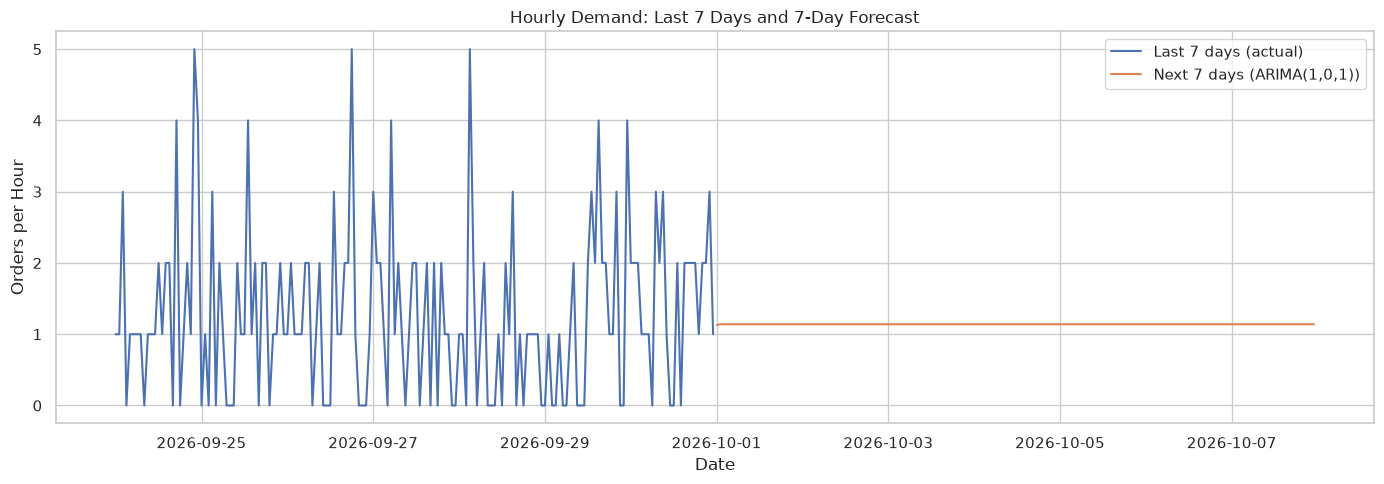

In [38]:
# Refit the selected demand model on the full history and forecast the next 7 days
FORECAST_HORIZON = 168
future_index = pd.date_range(
    demand_series.index[-1] + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON, freq="h"
)

if best_demand_model.startswith("ARIMA"):
    full_arima = ARIMA(demand_series, order=(1, 0, 1)).fit()
    future_values = full_arima.forecast(steps=FORECAST_HORIZON).clip(lower=0).to_numpy()
elif best_demand_model == "Prophet":
    full_prophet = make_prophet()
    full_prophet.fit(to_prophet_frame(demand_series))
    future_values = np.maximum(
        full_prophet.predict(pd.DataFrame({"ds": future_index}))["yhat"].to_numpy(), 0
    )
else:
    future_values = demand_series.iloc[-FORECAST_HORIZON:].to_numpy()

demand_forecast = pd.DataFrame({
    "forecast_timestamp": future_index,
    "predicted_orders": np.round(future_values, 2)
})
demand_forecast["hour"] = demand_forecast["forecast_timestamp"].dt.hour
demand_forecast["day_of_week"] = demand_forecast["forecast_timestamp"].dt.day_name()
demand_forecast["model"] = best_demand_model
display(demand_forecast.head())

plt.figure(figsize=(14, 5))
plt.plot(demand_series.index[-168:], demand_series.iloc[-168:].values, label="Last 7 days (actual)")
plt.plot(demand_forecast["forecast_timestamp"], demand_forecast["predicted_orders"],
         label=f"Next 7 days ({best_demand_model})")
plt.title("Hourly Demand: Last 7 Days and 7-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()
plt.show()

### 5.3 Integrated order-level table

In [39]:
integrated = delivery_df[[
    "order_id", "customer_id", "restaurant_id", "driver_id", "order_timestamp",
    "hour", "day_of_week", "is_weekend", "item_count", "order_amount", "total_amount",
    "distance_km", "prep_time_minutes", "weather", "traffic",
    "delivery_time_minutes", "predicted_delivery_time", "delay_vs_prediction", "in_test_set"
]].copy()

integrated = (
    integrated
    .merge(customer_features[["customer_id", "customer_segment"]],
           on="customer_id", how="left", validate="many_to_one")
    .merge(restaurant_features[["restaurant_id", "restaurant_segment", "cuisine", "city"]],
           on="restaurant_id", how="left", validate="many_to_one")
    .merge(reviews[["order_id", "rating", "sentiment", "predicted_sentiment"]],
           on="order_id", how="left", validate="one_to_one")
    .merge(payments[["order_id", "tip_amount", "payment_method"]],
           on="order_id", how="left", validate="one_to_one")
)

print("Integrated table:", integrated.shape)
display(integrated.head())

Integrated table: (4410, 28)


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,hour,day_of_week,is_weekend,item_count,order_amount,...,in_test_set,customer_segment,restaurant_segment,cuisine,city,rating,sentiment,predicted_sentiment,tip_amount,payment_method
0,O000001,C0400,R008,D0074,2026-05-25 01:22:00,1,Monday,False,2,474.01,...,False,Weekday Regular Customers,Fast-Prep Lower-Rated Restaurants,Fast Food,Mumbai,5.0,positive,positive,24.70,UPI
1,O000002,C0308,R022,D0068,2026-05-29 20:41:00,20,Friday,False,7,1476.33,...,False,Premium Frequent Diners,Highly Rated Niche Restaurants,Biryani,Delhi,NaN,NaN,NaN,75.32,Debit Card
2,O000003,C0029,R025,D0025,2026-07-08 13:58:00,13,Wednesday,False,1,154.74,...,False,Premium Frequent Diners,Highly Rated Niche Restaurants,Indian,Hyderabad,NaN,NaN,NaN,10.24,Cash
3,O000004,C0144,R002,D0013,2026-07-23 19:04:00,19,Thursday,False,1,144.95,...,False,Late-Night Budget Customers,Fast-Prep Lower-Rated Restaurants,Desserts,Pune,NaN,NaN,NaN,8.88,UPI
4,O000005,C0076,R009,D0081,2026-09-26 09:50:00,9,Saturday,True,7,1424.06,...,False,Late-Night Budget Customers,High-Demand Slow-Preparation Restaurants,Fast Food,Bengaluru,NaN,NaN,NaN,73.20,Credit Card
